# AKE Lab 7 · MLOps: Das Trägermodell vom Notebook zum Service — Lösung mit Dozentenhinweisen

**Angewandte KI & KI-Engineering · Block C – KI-Engineering & MLOps · Woche 7**
Bezug: Foliensatz *MLOps: Vom Notebook zum Produktivsystem*, Abschnitte 2 (Experiment Tracking), 3 (Model Registry),
4 (Modell als REST-API), 5 (Containerisierung) und 6 (CI/CD für ML) · Lektüre: Huyen (2022), *Designing Machine Learning
Systems*, Kap. 7

> **Dieses Notebook ist das komplette Lab – es gibt kein separates Aufgabenblatt.** Jede Aufgabe enthält die Aufgabenstellung,
> die Befehle, die Erwartungswerte und die Leitfragen. Der Code ist ausführlich kommentiert: Lesen Sie die Kommentare
> (Zeilen, die mit `#` beginnen) – sie erklären Zeile für Zeile, was passiert.

**Die Aufgabe:** Seit Lab 6 ist das Trägermodell reproduzierbar – aber es lebt nur in Ihrem Übungs-Repo `traeger-pipeline/`.
Niemand außer Ihnen kann es benutzen, und welcher Lauf welches Ergebnis hatte, steht nur in Ihrem Gedächtnis. Heute gehen Sie
den Weg bis zum laufenden Dienst: Sie **protokollieren** zwei Trainingsläufe mit MLflow, **registrieren** das bessere Modell
und laden es über den Alias `champion`, bauen mit FastAPI einen **Dienst** mit dem Endpunkt `/predict`, testen ihn mit pytest,
packen ihn in einen **Container** und lassen am Ende einen **CI-Workflow** alles prüfen.

**Charakter:** In der Vorlesung wird jeder Schritt dieses Labs **live am Beamer gezeigt**, jeweils direkt nach dem Vorlesungsabschnitt, zu dem er gehört. Sie schauen dort zu und bearbeiten das Lab anschließend **vollständig zu Hause**.
**Ihre Zeit ≈ 85 Min.** zu Hause, davon **≈ 3–6 Min. Rechenzeit** für zwei Trainingsläufe
(Referenz 4 Kerne / 8 GB, keine GPU) und – nur mit Docker – einige Minuten für den ersten Image-Build.

---
## 🎓 Hinweise für Lehrende (nur in dieser Lösung)

**Stand 15.11.2026 – reine Live-Demo.** In der Sitzung arbeitet niemand am eigenen Rechner. Diese Lösung ist das
Vorführ-Notebook: Nach jedem Vorlesungsabschnitt wird der passende Teil am Beamer gezeigt, die Studierenden bearbeiten das
Starter-Notebook vollständig zu Hause. Der Zeitplan weiter unten und die Minutenangaben in den Dozentenhinweisen stammen aus
der früheren Planung mit Arbeitsphasen und gelten nicht mehr.

| Live-Demo (Folie) | Zellen | Zeit | Hinweis |
|---|---|---|---|
| „Live: MLflow Tracking“ | 1.1, 1.2 (inkl. `mlflow ui`), danach Experiment `traeger-sweep` | 10 Min. | Vorhandene Läufe werden nicht wiederholt (≈ 80 s je Lauf). **Sweep vorab rechnen:** im Ordner `traeger-pipeline` mit aktivierter Kursumgebung `python "../02_Vorlesung und Skript/AKE_Woche07/demo/demo_sweep.py"` – acht Läufe im eigenen Experiment `traeger-sweep`, ≈ 11 Min.; das Experiment `traeger` des Labs bleibt unberührt. In der Oberfläche zusätzlich den Reiter *Artifacts* eines Laufs zeigen. |
| „Live: Registry und Alias“ | 1.3 (mit `PRINZIP`), 1.4 | 5 Min. | – |
| „Live: der Dienst“ | 2.1, 2.2, 2.3 (Fall a, bei Zeit c), 2.4 | 10 Min. | `/docs` im Browser zeigen |
| „Live: vom Dockerfile zum Container“ | 3.1, 3.3, 3.4 `AUSFÜHREN` | 7 Min. | Image vorher einmal bauen, sonst lädt der Build PyTorch im Hörsaal |
| „Live: die Pipeline prüft“ | 4.1, 4.2, 4.3 | 5 Min. | lokal im Notebook; GitHub nur, wenn dort schon ein Lauf durchgelaufen ist |

**Vor der Sitzung**

1. Ordner `lab07/` (Starter-Notebook + `vorlage/`) ins Kursrepository pushen; die Lösung bleibt per `.gitignore` lokal
   (`lab07/lab07_loesung.ipynb`, wie in Lab 5 und 6) und wird nach der Abgabe freigegeben.
2. **`uv sync` ansagen.** `pytest` und `httpx` sind neu in `pyproject.toml`/`uv.lock` (Befund 2 der Folien-Gliederung). Ohne
   `uv sync` scheitert Aufgabe 2.4 mit „No module named pytest“ – die Setup-Zelle prüft das.
3. Das Lab arbeitet im Übungs-Repo `traeger-pipeline/` aus Lab 6 (neben dem Kursordner). Wer Lab 6 nicht abgeschlossen hat,
   setzt in Aufgabe 0 `OHNE_LAB6 = True`; die Zelle baut den Stand in ≈ 2–4 Min. nach (DVC einrichten, `dvc repro`).
   **Vorab als Hausaufgabe ansagen**, sonst fehlt diese Zeit in Aufgabe 1.
4. **Docker:** Vor der Sitzung `docker pull python:3.12-slim` ansagen (≈ 45 MB komprimiert). Der erste Build lädt zusätzlich
   PyTorch-CPU (≈ 200 MB Download). Im Referenzlauf (Glasfaser) dauerte der kalte Build 58 s; im Hochschulnetz mit 25 Rechnern
   gleichzeitig eher 5–10 Min. Deshalb auf der Lab-Folie: Build starten, sobald das Dockerfile vollständig ist.
5. Für Aufgabe 4 (am Beamer): **eigenes GitHub-Repository vorbereiten** und je einen grünen und einen roten Lauf erzeugen.
   Der Workflow ist lokal geprüft (Job `test` in frischer Umgebung mit genau `requirements-ci.txt`: 5 passed; Job `image`:
   Build, Start, `/health`), aber **noch nicht auf GitHub gelaufen** – das Lösungs-Notebook pusht nichts.

**Zeitplan und gemessene Laufzeiten** (Referenzlauf: M4 Pro, 4 Threads, torch 2.8.0, MLflow 2.22.5, FastAPI 0.142.2,
Docker 28.5.2 linux/arm64)

| Block | nach Folie | Zeit | Rechenzeit M4 Pro | Erwartung Referenz-Laptop |
|---|---|---|---|---|
| A1 Tracking + Registry | „Beispiel: Alias umhängen“ | 20 Min. | 2 × ≈ 70–80 s Training (davon ≈ 6 s Modell loggen), gesamt ≈ 150–170 s | ≈ 2× so lang |
| A2 Service mit `/predict` | „Code: test_app.py“ | 25 Min. | Start des Dienstes ≈ 5 s, pytest ≈ 6 s, Anfrage ≈ 10 ms, gesamt 18 s | Start ≈ 10 s, Anfrage ≈ 30–60 ms |
| A3 Dockerfile + Container | „Wenn Docker nicht läuft“ | 25 Min. | Build ganz kalt 58 s, ohne Cache mit lokalem Grundsystem 67 s (Streuung durch das Netz), nach Änderung von `app.py` ≈ 2 s | Build kalt 5–10 Min. (Netz!) |
| A4 CI-Workflow | „Der ganze Kreis“ | 5 Min. + Hausaufgabe | Workflow von Hand ≈ 10 s | – |

Der Referenzlauf dieser Lösung (11.11.2026, 57 Prüfungen ✅, Gesamtlaufzeit 5 Min. 20 s) lief in einer **Kopie** des
Übungs-Repos `traeger-pipeline/` (Stand „Pipeline v3“, Commit `b5ae2be`); der lange Pfad dieser Kopie ist in den Ausgaben zu
`<Testordner>` gekürzt. Ihr eigenes Übungs-Repo wurde nicht verändert.

**Kontrollwerte für die Lab-Folien (ersetzen die „[nach Lösungslauf nachtragen]“-Stellen)**

- **Lab 1:** `val_accuracy` **0.984** (lr_backbone 0.0001) · **0.9541** (0.0002) – identisch mit den Pipeline-Ständen v1/v3 und v2.
  Laufzeit je Lauf ≈ 70 s (M4 Pro), davon Fine-Tuning 2 × 30 s. `mlruns/` nach zwei Läufen **≈ 90 MB** (2 × 44,8 MB
  `model.pth`; alles andere zusammen ≈ 10 kB). Daten-Tag `data_md5 bd5e89a8…` wie auf der Folie „Anschluss an DVC“.
- **Lab 2:** nach 2.1 **4 passed**, nach 2.4 **5 passed** (pytest ≈ 5 s) · `kirche.JPEG`: Klasse **Kirche, p = 1.0**
  (auf der Folie „Beispiel: Eine Anfrage, eine Antwort“ steht der Platzhalter 0.9712 → **1.0** eintragen) · Statuscodes:
  a) falscher Feldname **422** · b) „hallo“ **422** · c) Rauschbild **200** (Antwort „Fallschirm“, p = 0.5767) ·
  d) schwieriges Fallschirm-Bild **200** (Antwort „Kirche“, p = 0.7337) · Antwortzeit je Anfrage **≈ 10 ms** (Median aus 20,
  M4 Pro, ohne Netz) · Start des Dienstes ≈ 5 s.
- **Lab 3:** Image **1,44 GB** laut `docker image ls` (linux/arm64; Summe der Schichten laut `docker image history`
  ≈ 1,13 GB: Grundsystem 160 MB · PyTorch-CPU **726 MB** · übrige Pakete 196 MB · Modell 44,8 MB · Code < 0,1 MB).
  Build kalt **58 s** (davon PyTorch 21 s, übrige Pakete 13 s, Export des Images 13 s), nach Änderung von `app.py` **≈ 2 s**:
  Schritte 2–6 `CACHED`, 7–9 neu. **9 Bauschritte** (`[1/9]` … `[9/9]`); `ENV`, `EXPOSE`, `CMD` zählt BuildKit nicht mit.
  Build-Cache laut `docker system df` ≈ 1,6 GB. Den CUDA-Vergleichswert (≈ 5 GB laut Konzept) habe ich **nicht** gemessen:
  Auf arm64 gibt es kein CUDA-Wheel; auf einem x86-Rechner nachmessen oder die Zahl weiter als „laut Konzept“ kennzeichnen.
  Build-Kontext mit `.dockerignore` **44,8 MB in 12 Dateien** statt 458 MB (ganzer Ordner mit Bildern, DVC-Cache, `.git`, `mlruns`).
- **Lab 4:** Job `test` lokal ≈ 6 s (ohne Installation; die Installation von `requirements-ci.txt` dauerte in einer frischen
  Umgebung ≈ 10 s mit `uv`, auf dem GitHub-Runner mit `pip` erfahrungsgemäß 1–2 Min.) · Laufzeiten und Image-Größe auf dem
  Runner (linux/amd64) **nach dem ersten echten Lauf nachtragen**.

- **Zusatz Z1** (Alias umhängen): schwieriges Fallschirm-Bild – Version 1 (0.984): „Kirche“, p = 0.7337 · nach Umhängen **ohne**
  Neustart unverändert · nach Neustart mit Version 2 (0.9541): „Fallschirm“, p = 0.9795. Das insgesamt schlechtere Modell
  erkennt genau dieses Bild richtig – schöner Anlass für „eine Zahl über 501 Bilder sagt nichts über das einzelne Bild“.
- **Zusatz Z2** (Folie „Vorverarbeitung wie im Training“, bisher „[nach Lösungslauf nachtragen]“), 501 Validierungsbilder:
  importiert **0.984** (493) · ohne Normalisierung **0.9122** (457) · BGR statt RGB **0.9561** (479) ·
  `Resize((160, 160))` **0.984** (493) – **kein Effekt**, weil alle Bilder des Datensatzes schon 160 × 160 px sind
  (Datencheck Lab 6). Auf der Folie also nicht behaupten, dass die Verzerrung hier schadet; sie schadet erst bei
  Bildern mit anderem Seitenverhältnis – genau die bekommt ein Dienst im Betrieb.

**Abweichungen gegenüber dem Foliensatz (bitte in den Folien nachziehen)**

- **`requirements-service.txt` braucht `pandas`.** Mit der Liste von der Anhangfolie scheitert der Import von `mlflow.pytorch`
  im Container (`ModuleNotFoundError: No module named 'pandas'`) – `mlflow-skinny` bringt pandas nicht mit, der PyTorch-Flavor
  importiert es aber. Das ist exakt Fall B der Folie „Beispiel: Welche Stufe wird rot?“ – nur dass es hier beide Jobs trifft,
  weil `requirements-ci.txt` die Service-Liste einbindet.
- **Smoke-Test im Workflow: `--retry-all-errors` statt `--retry-connrefused`.** Mit der Zeile von der Folie wurde der
  Smoke-Test im Test rot: Der Port ist sofort nach `docker run -d` offen, uvicorn braucht aber noch ≈ 3–5 s zum Laden von
  PyTorch und Modell. In dieser Zeit bricht die Verbindung ab (`curl: (56) Recv failure: Connection reset by peer`) – das ist
  kein „connection refused“, und `curl` wiederholt dann **nicht**. `--retry-all-errors` (curl ≥ 7.71) wiederholt bei jedem
  Fehler. Bitte auf den Folien „Code: Workflow ci.yml“ und im Anhang ändern.
- **`.dockerignore` hat eine Zeile mehr:** `**/__pycache__` – sonst wandern die Zwischendateien aus `lab02/src/__pycache__`
  ins Image und der Cache-Schlüssel von `COPY lab02/src` hinge an der lokalen Python-Version.
- **`trainiere(P)` gibt drei Werte zurück** (`model, acc, beschreibung`) statt zwei; die Modellbeschreibung wird mit
  `mlflow.log_dict(beschreibung, "traeger_v1.yaml")` zum Run gelegt statt mit `log_artifact("models/traeger_v1.yaml")`.
  Grund: `models/traeger_v1.yaml` ist eine Ausgabe der DVC-Pipeline; würde das Tracking-Skript sie überschreiben, wäre nach
  dem zweiten Lauf `dvc status` nicht mehr sauber und die Datei beschriebe das falsche Modell.
- **Zweiter Lauf per Kommandozeile** (`--lr-backbone 0.0002`) statt über `params.yaml`: spart einen Commit, erzeugt aber
  bewusst einen Run, dessen `git_commit` nicht zu seinen Parametern passt (Leitfrage in 1.2).
- **Fünf statt vier Tests** nach 2.4 (`test_fallschirm`). Als Fallschirm-Bild dient `n03888257_11042.JPEG` – das **erste**
  Fallschirm-Bild der Validierungsliste (`ILSVRC2012_val_00038942.JPEG`) erkennt das Modell als Kirche (einer der 8 Fehler).
  Es liegt als `lab07/fallschirm_schwer.JPEG` bei und ist in 2.3 Fall d).
- **Eigenes Service-Repo für die CI** (`traeger-service/`, Aufgabe 4.1) statt das Übungs-Repo zu pushen. Grund:
  `models/traeger_v1.yaml` und `lab07/model/` stehen im Übungs-Repo in `.gitignore` (DVC-Ausgabe bzw. 45 MB Modell) – ein
  Checkout auf dem Runner hätte sie nicht, `COPY models/traeger_v1.yaml` würde scheitern. Das Service-Repo enthält genau die
  Dateien aus `.dockerignore` plus Tests und Workflow (≈ 45 MB, unter dem GitHub-Limit von 100 MB je Datei). Damit ist der
  offene Punkt der Lab-4-Folie („Vorlage-Repository oder Fork; Größe von lab07/model beachten“) entschieden.
- **„Im Editor und Terminal“** (Untertitel der Lab-Folien): Das Übungs-Repo liegt außerhalb des Jupyter-Startordners, der
  Dateibrowser erreicht es nicht. Deshalb schreibt jeweils eine Notebook-Zelle die Datei (`schreibe("lab07/app.py", …)`) und
  die Befehle laufen über `run("…")` bzw. `starte(…)`. Wer mag, nimmt das Jupyter-Terminal – die Befehle sind dieselben.
- **Port 5000** ist auf macOS meist vom AirPlay-Empfänger belegt; `starte()` nimmt dann automatisch 5001.

**Häufige Stolpersteine**

- *`uv sync` vergessen* → Setup meldet ❌ bei pytest.
- *Zelle 1.3 zweimal ausgeführt* → Version 2 desselben Runs, der Alias wandert. Harmlos und sogar eine Leitfrage.
- *Dienst läuft noch* (Port belegt): `stoppe()` in einer Zelle ausführen; die Hilfsfunktion sucht sonst den nächsten freien Port.
- *Windows-Firewall* fragt beim ersten Start von uvicorn nach – „Zugriff auf private Netzwerke“ genügt.
- *Docker nicht gestartet* („Cannot connect to the Docker daemon“): Docker Desktop öffnen, 30 s warten, Zelle 3.3 erneut.
- *Proxy/VPN:* Anfragen an `127.0.0.1` gehen im Notebook bewusst am Proxy vorbei; im Browser ggf. `localhost` statt
  `127.0.0.1` probieren.
- *MLflow-Warnungen* („Model logged without a signature“, „Failed to resolve installed pip version“) blendet `run()` aus.
  Die Signatur wäre der nächste Schritt (Eingabeformat am Modell dokumentieren) – für das Capstone erwähnen.
- *`requirements.txt` im Modellordner* enthält auch Pakete, die der Dienst nicht braucht (transformers, lightning …):
  MLflow leitet die Liste aus den geladenen Modulen der Kursumgebung ab. Guter Anlass für die Frage in 1.3, warum wir für
  den Container eine eigene, kurze Liste pflegen.
---

## Organisatorisches

| | |
|---|---|
| **Termin** | Woche 7 (KW 47, 19.11.2026), in der Vorlesung fünf Live-Demos am Beamer (MLflow, Registry, Dienst, Container, CI); Bearbeitung des Labs zu Hause |
| **Bezug** | Foliensatz *MLOps: Vom Notebook zum Produktivsystem*, Abschn. 2–6 |
| **Material** | Ordner `lab07/` im Kursrepository: dieses Notebook und `vorlage/` (`lab07/training.py`, `requirements-service.txt`, `requirements-ci.txt`, `.dockerignore`, `.github/workflows/ci.yml`); die Musterlösung folgt nach der Abgabe |
| **Umgebung** | Kursumgebung aktualisieren: `git pull`, danach **`uv sync`** (neu: pytest). MLflow 2.22.5, FastAPI 0.142.2 und uvicorn 0.54.0 sind schon enthalten. Für Aufgabe 3 **Docker Desktop** (oder Podman) – wenn das nicht läuft: Fallback-Kette, siehe dort. Für Aufgabe 4 ein **GitHub-Konto**. |
| **Voraussetzung** | Ihr Übungs-Repo `traeger-pipeline/` aus Lab 6 (neben dem Kursordner) mit durchgelaufener Pipeline. Fehlt es: in Aufgabe 0 `OHNE_LAB6 = True` setzen. |

**Fahrplan**

| Aufgabe | In der Vorlesung live gezeigt (Folie) | Inhalt | Ihre Zeit | Rechenzeit |
|---|---|---|---|---|
| 0 · Setup | – | Pfade, Hilfsfunktionen, Prüfungen | 2 Min. | Sekunden |
| 1 · Tracking und Registry | „Live: MLflow Tracking“ und „Live: Registry und Alias“ | Lauf protokollieren (`LIVE`), zweiter Lauf (`CODE`), `mlruns/` von Hand lesen (`PRINZIP`), registrieren + Alias (`CODE`, `PRINZIP`), über den Alias laden (`CODE`) | 20 Min. | ≈ 3–6 Min. |
| 2 · Service mit `/predict` | „Live: der Dienst“ | `app.py` (`LIVE`), starten und anfragen (`CODE`), der Weg einer Anfrage von Hand (`PRINZIP`), Fehlerfälle (`CODE`), Tests (`CODE`) | 25 Min. | Sekunden |
| 3 · Dockerfile und Container | „Live: vom Dockerfile zum Container“ | Modell exportieren (`LIVE`), Dockerfile (`CODE`), Build-Kontext und Build-Cache von Hand (`PRINZIP`), bauen und starten (`CODE`), Cache beobachten (`CODE`) | 25 Min. | Build: Minuten (Netz) |
| 4 · CI-Workflow | „Live: die Pipeline prüft“ | Service-Repo (`LIVE`), Workflow von Hand ausführen (`PRINZIP`), absichtlich rot (`CODE`), Abgabe | 15 Min. | Sekunden |
| Zusatz | zu Hause | Alias umhängen und zurückrollen; falsche Vorverarbeitung nachmessen | – | ≈ 1 Min. |

**Kennzeichnung der Arbeitsarten** (steht am Anfang jeder Teilaufgabe):

| Marke | Was Sie tun |
|---|---|
| `LIVE` | wurde in der Vorlesung am Beamer gezeigt – zu Hause selbst ausführen und nachvollziehen; kleine Lücken füllen Sie mit Hilfe der Folien |
| `CODE` | eine Lücke selbst füllen. **Python-Code:** die Zeile `raise NotImplementedError("TODO …")` durch Ihre Lösung ersetzen – der Kommentar `# TODO …` darüber darf stehen bleiben. **Dockerfile:** dort gibt es kein `raise` – Sie ersetzen die Kommentarzeile `# TODO …` selbst |
| `PRINZIP` | ausführen und lesen – bewusst einfacher Code, der zeigt, was das Werkzeug intern tut, und am Ende mit dem Werkzeug vergleicht; oft mit einer kleinen Lücke |
| `AUSFÜHREN` | nur ausführen und die Ausgabe lesen |
| `DENKEN` | Interpretationsfrage in der Markdown-Zelle beantworten |

Wer bei einer Lücke nicht weiterkommt: Die gesuchten Zeilen stehen auf den Folien (Anhang „Code“ und Vertiefung). Die Aufgaben bauen aufeinander auf.

**Abgabe** (Weg und Termin: siehe Folie „Organisatorisches – Lab Woche 7“): das **Dockerfile**, der **Link zum grünen CI-Lauf** in Ihrem GitHub-Repository
und dieses Notebook mit Ihren Antworten auf die `DENKEN`-Fragen. Die letzte Zelle packt Dockerfile, `app.py`, `test_app.py`
und den Workflow in ein ZIP. **Bewertet werden Dockerfile und CI-Log – nicht, ob der Build auf Ihrem Laptop lief.**

## Lernziele

Nach dem Lab können Sie …

- **Verstehen:** erklären, was ein MLflow-Run festhält (Parameter, Metriken, Tags, Artefakte), wo das auf der Festplatte
  liegt und wie ein Alias in der Registry auf eine Modellversion zeigt.
- **Anwenden:** einen Trainingslauf protokollieren, das beste Modell registrieren und über `models:/traeger@champion` laden.
- **Anwenden:** ein Modell mit FastAPI als Dienst bereitstellen – mit Schema für Anfrage und Antwort – und mit pytest testen.
- **Analysieren:** für eine fehlerhafte Anfrage vorhersagen, welche Station des Dienstes sie mit welchem Statuscode ablehnt.
- **Analysieren:** für ein Dockerfile vorhersagen, welche Schichten nach einer Änderung neu gebaut werden, und ein CI-Log lesen.
- **Bewerten:** entscheiden, was ein Test, ein Smoke-Test und ein Statuscode 200 jeweils zusichern – und was nicht.

## Spielregeln und Hinweise

- **Sie arbeiten im Übungs-Repo.** Alle Dateien dieses Labs entstehen in `traeger-pipeline/lab07/` (neben dem Kursordner),
  nicht im Kursordner. Jupyter kann diesen Ordner im Dateibrowser nicht anzeigen – deshalb **schreibt eine Zelle die Datei**:
  `schreibe("lab07/app.py", "…Inhalt…")`. Sie ändern den Text in der Zelle und führen sie erneut aus.
- **Befehle laufen über `run("…")`.** Die Hilfsfunktion führt einen Befehl im Übungs-Repo aus und zeigt die Ausgabe so, wie
  Sie sie im Terminal sähen (`$ befehl` und darunter die Antwort). Wer lieber tippt: Im Jupyter-Terminal
  (*File → New → Terminal*) mit `cd` in den Ordner `traeger-pipeline` wechseln – die Befehle sind dieselben.
- **Dienste laufen im Hintergrund.** `starte("dienst", "uvicorn lab07.app:app --port …", port)` startet ein Programm, das
  weiterläuft, während Sie die nächsten Zellen ausführen; `stoppe("dienst")` beendet es. Die Ausgabe des Programms steht in
  `lab07/results/<name>.log` (im Kursordner – das können Sie in Jupyter öffnen).
- **Immer aus dem Hauptordner.** Alle Befehle gehen davon aus, dass sie im Hauptordner des Übungs-Repos starten
  (`lab02/`, `lab07/` und `models/` liegen direkt darunter). `run()` und `starte()` sorgen dafür.
- **Immer von oben nach unten.** Spätere Zellen brauchen die Dateien und Variablen der früheren. Eine Zelle zweimal
  auszuführen ist harmlos; Trainingsläufe werden dabei nicht wiederholt (das Notebook merkt, dass der Lauf schon existiert).

## Kurzhilfe: Notebook, Python und die Befehle dieses Labs

**Bedienung:** Zelle auswählen und mit **Shift + Enter** ausführen. Nach einem Fehler die Zelle korrigieren und erneut ausführen.

| Sie sehen im Code … | Bedeutung |
|---|---|
| `# Text` | Kommentar – wird nicht ausgeführt, erklärt nur |
| `run("python lab07/train_tracked.py")` | führt den Befehl im Übungs-Repo aus und zeigt die Ausgabe |
| `run("…", umgebung={"MODEL_URI": "lab07/model"})` | derselbe Befehl, aber mit einer zusätzlichen **Umgebungsvariable** |
| `schreibe("lab07/app.py", r"""…""")` | legt eine Datei mit diesem Inhalt im Übungs-Repo an (überschreibt die alte) |
| `starte("dienst", "…", port)` · `stoppe("dienst")` | Programm im Hintergrund starten · beenden |
| `frage(URL, "/health")` · `frage(URL, "/predict", {...})` | HTTP-Anfrage schicken: GET · POST mit JSON-Körper; Rückgabe `(Statuscode, Antwort)` |
| `ARBEIT / "lab07" / "app.py"` | Pfad zusammensetzen (`Path`-Objekt) – funktioniert unter Windows, macOS und Linux |
| `d = {"a": 1}`, `d["a"]`, `"a" in d` | *Dictionary* (Schlüssel → Wert) – JSON wird in Python zu einem Dictionary |
| `for x in liste:` | Schleife: Der eingerückte Block läuft für jedes Element |
| `f"{x:.4f}"` | *f-String*: setzt `x` mit vier Nachkommastellen in den Text ein |
| `class Anfrage(BaseModel): image_b64: str` | *Schema*: Eine Anfrage muss ein Feld `image_b64` mit einem Text enthalten |
| `@app.post("/predict")` | *Dekorator*: Die Funktion darunter beantwortet POST-Anfragen an `/predict` |
| `check("Name", lambda: ...)` | Prüfzelle: zeigt ✅, wenn die Bedingung hinter `lambda:` wahr ist, sonst ❌ mit Hinweis |
| `raise NotImplementedError("TODO …")` | Platzhalter in einer Python-Lücke: Diese Zeile ersetzen Sie durch Ihre Lösung (der Kommentar `# TODO …` darüber darf stehen bleiben) |

| Befehl | Was er tut |
|---|---|
| `python lab07/train_tracked.py [--lr-backbone 0.0002]` | Trägermodell trainieren und den Lauf protokollieren |
| `mlflow ui [--port 5001]` | Tracking-Oberfläche für `./mlruns` im Browser |
| `uvicorn lab07.app:app [--port 8001]` | Dienst starten: „im Paket `lab07` die Datei `app.py`, darin das Objekt `app`“ |
| `python -m pytest lab07 -q` | alle Tests in `lab07/` ausführen (`-q` = kurze Ausgabe) |
| `docker build -t traeger-service -f lab07/Dockerfile .` | Image bauen; der Punkt = Hauptordner als Build-Kontext |
| `docker run -d --rm --name traeger-service -p 8000:8000 traeger-service` | Container im Hintergrund starten, Port nach außen verbinden |
| `docker ps` · `docker logs <name>` · `docker stop <name>` | laufende Container · Ausgabe eines Containers · stoppen |
| `docker image ls` · `docker image history traeger-service` | Images mit Größe · Schichten eines Images |
| `git add …` · `git commit -m "…"` · `git push` | Stand festhalten · zum Server schicken (der Push startet die CI) |

**Statuscodes, die heute vorkommen:** `200` Anfrage verarbeitet · `404` Adresse gibt es nicht · `405` falsche Methode
(GET statt POST) · `422` Anfrage verstanden, aber Inhalt passt nicht zum Schema.

## Aufgabe 0 · Setup

`AUSFÜHREN` · Bibliotheken laden, Pfade festlegen, die Hilfsfunktionen bereitstellen und prüfen, ob alles da ist. Wenn alle
Zeilen ✅ zeigen, kann es losgehen. Die Docker-Zeile ist nur eine Information – Aufgaben 1 und 2 brauchen kein Docker.

**Lab 6 nicht abgeschlossen?** Dann zeigt die Prüfung „Übungs-Repo aus Lab 6“ ein ❌. Setzen Sie in der ersten Zeile
`OHNE_LAB6 = True` und führen Sie die Zelle erneut aus: Sie legt das Übungs-Repo an und lässt die Pipeline einmal laufen
(≈ 2–4 Min.).

In [1]:
OHNE_LAB6 = False      # True: Uebungs-Repo traeger-pipeline/ hier neu anlegen und die Pipeline aus Lab 6 einmal laufen lassen

# --- Bibliotheken -------------------------------------------------------------------------------------------
import os, re, sys, time, json, shutil, shlex, subprocess, hashlib, types, stat      # Standardbibliothek
import base64, io, socket, signal, atexit, zipfile                                   # Standardbibliothek (Netz, Dateien)
import urllib.request, urllib.error, urllib.parse                                    # HTTP-Anfragen ohne Zusatzpaket
from pathlib import Path                         # Pfade zu Dateien und Ordnern, unabhaengig vom Betriebssystem
import numpy as np                               # Rechnen mit Vektoren und Matrizen
import pandas as pd                              # Tabellen (DataFrame)
import matplotlib.pyplot as plt                  # Diagramme und Bilder
import yaml                                      # YAML-Dateien lesen (params.yaml, meta.yaml, ci.yml)
from PIL import Image                            # Bilder oeffnen
os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"   # keine Fortschrittsbalken beim Kopieren von Modellen
import mlflow, mlflow.pytorch                    # Experiment Tracking und Model Registry
from mlflow import MlflowClient
import torch
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# --- Pruefhelfer --------------------------------------------------------------------------------------------
# check("Name", Bedingung, "Hinweis") gibt ✅ aus, wenn die Bedingung wahr ist, sonst ❌ mit Hinweis.
# Die Bedingung steht meist als `lambda: ...` da: eine kleine Funktion, die erst hier ausgewertet wird.
CHECKS = {}
def check(name, ok, hint=""):
    try:
        ok = bool(ok() if callable(ok) else ok); msg = hint
    except NotImplementedError as e:             # die Luecke ist noch nicht gefuellt
        ok, msg = False, f"{e} ist noch offen"
    except Exception as e:                       # irgendein anderer Fehler
        ok, msg = False, f"{type(e).__name__}: {e}" + (f" | {hint}" if hint else "")
    CHECKS[name] = ok
    print(f"✅ {name}" if ok else f"❌ {name} – Hinweis: {msg}")

def nah(a, b, tol):                              # |a - b| <= tol  (fuer Kontrollwerte mit Rundung)
    return abs(float(a) - float(b)) <= tol

# --- Laufzeitmessung je Aufgabe (Tabelle am Ende; fuer das Lab nicht wichtig) ---------------------------------
RUNTIME, _teil = {}, {"name": "Aufgabe 0", "t0": None}
def abschnitt(name): _teil["name"] = name
def _ake_pre(*a): _teil["t0"] = time.perf_counter()
def _ake_post(*a):
    if _teil["t0"] is not None:
        RUNTIME[_teil["name"]] = RUNTIME.get(_teil["name"], 0.0) + time.perf_counter() - _teil["t0"]
try:
    _ip = get_ipython()
    for ev, fn in (("pre_run_cell", _ake_pre), ("post_run_cell", _ake_post)):
        for old in [f for f in _ip.events.callbacks[ev] if getattr(f, "__name__", "") == fn.__name__]:
            _ip.events.unregister(ev, old)
        _ip.events.register(ev, fn)
except NameError:
    pass

# --- Pfade ----------------------------------------------------------------------------------------------------
# REPO_ROOT = Kursordner (erster Elternordner mit pyproject.toml). Das Uebungs-Repo ARBEIT (aus Lab 6) liegt DANEBEN,
# das Service-Repo SERVICE (Aufgabe 4) wird daneben angelegt. Andere Orte: Umgebungsvariable setzen oder hier eintragen.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Kein Kursrepository gefunden. Bitte Jupyter im Ordner des Repositorys starten und lab07/ oeffnen.")
DATA    = REPO_ROOT / "data"
VORLAGE = REPO_ROOT / "lab07" / "vorlage"                     # training.py, requirements-*.txt, .dockerignore, ci.yml
ARBEIT  = Path(os.environ.get("AKE_LAB07_ARBEIT", os.environ.get("AKE_LAB06_ARBEIT", REPO_ROOT.parent / "traeger-pipeline"))).resolve()
SERVICE = Path(os.environ.get("AKE_LAB07_SERVICE", ARBEIT.parent / "traeger-service")).resolve()
RESULTS = Path("results").resolve(); RESULTS.mkdir(exist_ok=True)

# --- run(): einen Befehl im Uebungs-Repo ausfuehren ---------------------------------------------------------------
# Was die Funktion tut:
#   1. Den Befehl in seine Teile zerlegen ("python -m pytest lab07" -> ["python", "-m", "pytest", "lab07"]).
#   2. "python", "mlflow", "uvicorn", "dvc" durch "<diese Python-Umgebung> [-m ...]" ersetzen - so laeuft garantiert
#      das Programm der Kursumgebung, auch wenn im System ein anderes Python installiert ist.
#   3. Den Befehl im Ordner ARBEIT starten und jede Ausgabezeile sofort anzeigen (wie im Terminal).
# umgebung={...} setzt zusaetzliche Umgebungsvariablen nur fuer diesen Befehl. nur="..." zeigt nur Zeilen, die auf das
# Muster passen (fuer sehr lange Ausgaben wie docker build). Rueckgabe: Objekt mit .ok, .ausgabe (Text), .sekunden.
RAUSCHEN = ("Failed to resolve installed pip version", "Model logged without a signature",
            "To enable auto staging", "dvc config core.autostage true")       # Hinweiszeilen, die nur ablenken
SPINNER = set("⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏")                                           # Zeichen von Fortschrittsanzeigen
LAUFZEITEN = {}                                                               # Laufzeit je Befehl (Tabelle am Ende)
MODULE = {"mlflow": "mlflow", "uvicorn": "uvicorn", "dvc": "dvc", "pytest": "pytest"}

def _teile(befehl):
    teile = shlex.split(befehl) if isinstance(befehl, str) else [str(t) for t in befehl]
    if teile[0] == "python":
        teile = [sys.executable] + teile[1:]
    elif teile[0] in MODULE:
        teile = [sys.executable, "-m", MODULE[teile[0]]] + teile[1:]
    return teile

def _env(umgebung=None):
    env = dict(os.environ, PATH=str(Path(sys.executable).parent) + os.pathsep + os.environ.get("PATH", ""),
               PYTHONUNBUFFERED="1", PYTHONWARNINGS="ignore", DVC_NO_ANALYTICS="1", GIT_PAGER="cat", PAGER="cat",
               TERM="dumb", GIT_TERMINAL_PROMPT="0", MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR="false")
    env.pop("MLFLOW_TRACKING_URI", None)          # Befehle sollen ./mlruns im Uebungs-Repo benutzen (Standard von MLflow)
    env.update({k: str(v) for k, v in (umgebung or {}).items()})
    return env

def run(befehl, erwarte_fehler=False, zeigen=True, cwd=None, umgebung=None, nur=None):
    teile = _teile(befehl)
    text = befehl if isinstance(befehl, str) else " ".join(str(t) for t in befehl)
    if umgebung:
        text = " ".join(f"{k}={v}" for k, v in umgebung.items()) + " " + text
    if zeigen:
        print(f"$ {text}", flush=True)
    t0 = time.perf_counter()
    try:
        p = subprocess.Popen(teile, cwd=cwd or ARBEIT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                             text=True, encoding="utf-8", errors="replace", env=_env(umgebung))
    except FileNotFoundError:
        print(f"❌ Programm '{teile[0]}' nicht gefunden."); return types.SimpleNamespace(ok=False, ausgabe="", sekunden=0)
    zeilen, gezeigt = [], set()
    for zeile in p.stdout:                                  # Zeile fuer Zeile, waehrend der Befehl laeuft
        zeile = re.sub(r"\x1b\[[0-9;?]*[A-Za-z]", "", zeile).rstrip()   # Steuerzeichen fuer Farben entfernen
        if any(r in zeile for r in RAUSCHEN) or zeile.lstrip()[:1] in SPINNER or (not zeile and (not zeilen or not zeilen[-1])):
            continue                                        # Hinweis-, Fortschritts- und doppelte Leerzeilen weglassen
        zeilen.append(zeile)
        if zeigen and (nur is None or (re.search(nur, zeile) and zeile not in gezeigt)):
            print("   " + zeile, flush=True); gezeigt.add(zeile)   # bei gefilterter Ausgabe jede Zeile nur einmal
    p.wait()
    erg = types.SimpleNamespace(ok=(p.returncode == 0), ausgabe="\n".join(zeilen), sekunden=time.perf_counter() - t0)
    LAUFZEITEN[f"{len(LAUFZEITEN) + 1:3d}: {text}"[:70]] = erg.sekunden
    if not erg.ok and nur is not None and zeigen:            # bei gefilterter Ausgabe im Fehlerfall das Ende ungefiltert zeigen
        print("   ...\n" + "\n".join("   " + z for z in zeilen[-25:]))
    if not erg.ok and not erwarte_fehler:
        raise RuntimeError(f"Befehl fehlgeschlagen (Rueckgabewert {p.returncode}): {text} – Ausgabe oben lesen.")
    if not erg.ok and zeigen:
        print("   (Fehler war hier erwartet bzw. erlaubt – Meldung lesen!)")
    return erg

# --- schreibe(): eine Datei im Uebungs-Repo anlegen ------------------------------------------------------------------
# Jupyter erreicht den Ordner traeger-pipeline/ im Dateibrowser nicht - deshalb ist die Notebook-Zelle unser Editor.
# Woran erkennt schreibe() eine noch nicht gefuellte Luecke?
#   Python-Datei (.py):        an der Platzhalterzeile raise NotImplementedError("TODO ...") - der Kommentar "# TODO ..."
#                              darueber zaehlt nicht und darf stehen bleiben.
#   andere Datei (Dockerfile): dort gibt es kein raise - die Luecke ist die Kommentarzeile "# TODO ...: Hinweis" selbst.
OFFEN_PY = re.compile(r'^[ \t]*raise NotImplementedError\("(TODO [^"]+)"\)', re.M)
OFFEN_SONST = re.compile(r"^[ \t]*# (TODO [0-9a-z.]+): ", re.M)
def schreibe(relpfad, text, basis=None):
    ziel = (basis or ARBEIT) / relpfad
    ziel.parent.mkdir(parents=True, exist_ok=True)
    text = text.strip("\n") + "\n"
    ziel.write_text(text, encoding="utf-8", newline="\n")
    print(f"geschrieben: {relpfad} ({len(text.splitlines())} Zeilen)")
    ist_python = relpfad.endswith(".py")
    luecke = (OFFEN_PY if ist_python else OFFEN_SONST).search(text)
    if luecke:                                               # Luecke noch offen -> hier anhalten statt spaeter raetseln
        was = "die Zeile mit raise NotImplementedError" if ist_python else "die Kommentarzeile # TODO"
        raise NotImplementedError(f"{luecke.group(1)} in {relpfad} – {was} durch Ihre Loesung ersetzen")
    if ist_python:
        compile(text, relpfad, "exec")                       # Tippfehler/Einrueckung sofort melden (SyntaxError)
    return ziel

def zeige_datei(relpfad, basis=None, von=1, bis=None):
    """Datei mit Zeilennummern ausgeben."""
    zeilen = ((basis or ARBEIT) / relpfad).read_text(encoding="utf-8").splitlines()
    print(f"--- {relpfad}")
    for nr, z in list(enumerate(zeilen, 1))[von - 1:bis]:
        print(f"{nr:3d}  {z}")

def loesche(ordner):
    """Ordner samt Inhalt loeschen - auch schreibgeschuetzte Dateien (Git/DVC schuetzen Dateien, Windows verweigert sonst)."""
    def _schreibbar_machen(func, pfad, exc):
        os.chmod(pfad, stat.S_IWRITE); func(pfad)
    shutil.rmtree(ordner, onexc=_schreibbar_machen)

# --- starte() / stoppe(): Programme im Hintergrund (mlflow ui, uvicorn) ---------------------------------------------
HINTERGRUND = globals().get("HINTERGRUND", {})                # Name -> (Prozess, Logdatei, Pfad der Logdatei)
OHNE_PROXY = urllib.request.build_opener(urllib.request.ProxyHandler({}))   # Anfragen an 127.0.0.1 nie ueber einen Proxy

def port_frei(port):
    """True, wenn auf diesem Port noch kein Programm lauscht."""
    with socket.socket() as s:
        s.settimeout(0.3)
        return s.connect_ex(("127.0.0.1", port)) != 0        # Verbindung scheitert -> Port ist frei

def freier_port(*kandidaten):
    """Ersten freien Port aus der Liste liefern."""
    for port in kandidaten:
        if port_frei(port):
            return port
    raise RuntimeError(f"Alle Ports belegt: {kandidaten} – laufende Dienste mit stoppe() beenden.")

def stoppe(name=None):
    """Ein Hintergrundprogramm beenden (ohne Namen: alle)."""
    for n in ([name] if name else list(HINTERGRUND)):
        if n not in HINTERGRUND:
            continue
        p, f, log = HINTERGRUND.pop(n)
        if p.poll() is None:
            if os.name == "nt":                              # Windows: Prozess samt Kindprozessen beenden
                subprocess.run(["taskkill", "/F", "/T", "/PID", str(p.pid)], capture_output=True)
            else:                                            # macOS/Linux: die ganze Prozessgruppe beenden
                try: os.killpg(p.pid, signal.SIGTERM)
                except ProcessLookupError: pass
            try: p.wait(10)
            except subprocess.TimeoutExpired: p.kill()
        f.close()
        print(f"⏹ {n} gestoppt")
atexit.register(stoppe)                                       # beim Beenden des Kernels aufraeumen

def warte_auf(url, sekunden=60, prozess=None):
    """Warten, bis unter url eine Antwort kommt. Rueckgabe: Wartezeit in Sekunden (oder None)."""
    t0 = time.perf_counter()
    while time.perf_counter() - t0 < sekunden:
        if prozess is not None and prozess.poll() is not None:
            return None                                      # Programm hat sich beendet
        try:
            OHNE_PROXY.open(url, timeout=2).read(); return time.perf_counter() - t0
        except urllib.error.HTTPError:
            return time.perf_counter() - t0                  # Server antwortet (wenn auch mit Fehlercode)
        except Exception:
            time.sleep(0.4)
    return None

def starte(name, befehl, port, pfad="/", umgebung=None, sekunden=90):
    """Befehl im Uebungs-Repo im Hintergrund starten und warten, bis http://127.0.0.1:<port><pfad> antwortet."""
    stoppe(name)
    log = RESULTS / f"{name}.log"
    f = open(log, "w", encoding="utf-8")
    extra = {"creationflags": subprocess.CREATE_NEW_PROCESS_GROUP} if os.name == "nt" else {"start_new_session": True}
    text = (" ".join(f"{k}={v}" for k, v in (umgebung or {}).items()) + " " + befehl).strip()
    print(f"$ {text}   (im Hintergrund)", flush=True)
    p = subprocess.Popen(_teile(befehl), cwd=ARBEIT, stdout=f, stderr=subprocess.STDOUT, env=_env(umgebung), **extra)
    HINTERGRUND[name] = (p, f, log)
    url = f"http://127.0.0.1:{port}"
    gewartet = warte_auf(url + pfad, sekunden, p)
    if gewartet is None:
        f.flush(); ende = "\n".join(log.read_text(encoding="utf-8", errors="replace").splitlines()[-15:])
        stoppe(name)
        raise RuntimeError(f"{name} ist nicht gestartet. Ende von {log.name}:\n{ende}")
    print(f"✅ {name} laeuft nach {gewartet:.1f} s: {url}{pfad}   (Protokoll: results/{log.name}, beenden: stoppe(\"{name}\"))")
    return url

# --- frage(): eine HTTP-Anfrage schicken ----------------------------------------------------------------------------
def kurz(obj, n=60):
    """Lange Texte in einer Antwort/Anfrage fuer die Anzeige kuerzen."""
    if isinstance(obj, dict): return {k: kurz(v, n) for k, v in obj.items()}
    if isinstance(obj, list): return [kurz(v, n) for v in obj]
    if isinstance(obj, str) and len(obj) > n: return obj[:24] + f"… ({len(obj)} Zeichen)"
    return obj

def frage(url, pfad, daten=None, zeigen=True):
    """GET (ohne daten) oder POST mit JSON-Koerper (daten = Dictionary). Rueckgabe: (Statuscode, Antwort als Dictionary)."""
    methode = "GET" if daten is None else "POST"
    koerper = None if daten is None else json.dumps(daten).encode("utf-8")       # Dictionary -> JSON-Text -> Bytes
    req = urllib.request.Request(url + pfad, data=koerper, method=methode, headers={"Content-Type": "application/json"})
    t0 = time.perf_counter()
    try:
        with OHNE_PROXY.open(req, timeout=60) as r:
            status, text = r.status, r.read().decode("utf-8")
    except urllib.error.HTTPError as e:                      # Statuscodes ab 400 kommen als Ausnahme
        status, text = e.code, e.read().decode("utf-8")
    ms = (time.perf_counter() - t0) * 1000
    try: antwort = json.loads(text)
    except json.JSONDecodeError: antwort = {"text": text}
    if zeigen:
        print(f"{methode} {pfad}" + (f"  {json.dumps(kurz(daten), ensure_ascii=False)}" if daten is not None else ""))
        print(f"   -> {status} in {ms:.0f} ms: {json.dumps(kurz(antwort, 200), ensure_ascii=False)}")
    return status, antwort

# --- MLflow im Notebook auf denselben Ordner zeigen lassen wie die Befehle im Uebungs-Repo -------------------------
mlflow.set_tracking_uri((ARBEIT / "mlruns").as_uri())        # file:///.../traeger-pipeline/mlruns
SPALTEN = {"tags.mlflow.runName": "name", "params.lr_backbone": "lr_backbone", "params.epochs": "epochs",
           "metrics.val_accuracy": "val_accuracy", "tags.git_commit": "git_commit", "tags.data_md5": "data_md5"}
def laeufe():
    """Alle Runs des Experiments 'traeger' als Tabelle: beste val_accuracy zuerst, bei Gleichstand der aeltere Lauf."""
    if not (ARBEIT / "mlruns").exists() or mlflow.get_experiment_by_name("traeger") is None:
        return pd.DataFrame(columns=["run_id", *SPALTEN.values()])
    df = mlflow.search_runs(experiment_names=["traeger"],
                            order_by=["metrics.val_accuracy DESC", "attributes.start_time ASC"])
    df = df[df["status"] == "FINISHED"] if "status" in df else df
    for spalte in SPALTEN:                                    # fehlende Spalten ergaenzen (z. B. wenn noch kein Lauf Tags hat)
        if spalte not in df: df[spalte] = None
    return df[["run_id", *SPALTEN]].rename(columns=SPALTEN).reset_index(drop=True)

def lauf_da(lr):
    """Gibt es schon einen abgeschlossenen Lauf mit dieser Lernrate im Backbone?"""
    return any(x is not None and nah(x, lr, 1e-9) for x in laeufe()["lr_backbone"])

# --- Notfall: Stand aus Lab 6 hier nachbauen ----------------------------------------------------------------------
def lab6_stand_da():
    return all((ARBEIT / f).exists() for f in (".git", "params.yaml", "data/imagenette5.dvc", "lab02/src/traeger.py",
               "lab06/data/manifest.csv", "lab06/cache/features_resnet18_160_train.pt", "models/traeger_v1.yaml"))

if OHNE_LAB6 and not lab6_stand_da():
    if ARBEIT.exists() and any(ARBEIT.iterdir()):
        raise RuntimeError(f"{ARBEIT} existiert schon, ist aber unvollstaendig. Bitte den Ordner umbenennen oder loeschen und die Zelle erneut ausfuehren.")
    print("Lege das Uebungs-Repo an und lasse die Pipeline aus Lab 6 einmal laufen (ca. 2-4 Min.) ...")
    V6 = REPO_ROOT / "lab06" / "vorlage"
    ARBEIT.mkdir(parents=True, exist_ok=True)
    (ARBEIT / ".ake_lab06").write_text("angelegt von lab07 (OHNE_LAB6)\n")
    shutil.copytree(DATA / "imagenette5", ARBEIT / "data" / "imagenette5")
    (ARBEIT / "data" / "models").mkdir()
    shutil.copy2(DATA / "models" / "resnet18-f37072fd.pth", ARBEIT / "data" / "models")
    (ARBEIT / "models").mkdir()
    shutil.copy2(REPO_ROOT / "models" / "traeger_v1.yaml.template", ARBEIT / "models")
    shutil.copytree(REPO_ROOT / "lab02" / "src", ARBEIT / "lab02" / "src", ignore=shutil.ignore_patterns("__pycache__"))
    shutil.copytree(V6, ARBEIT, dirs_exist_ok=True, ignore=shutil.ignore_patterns("__pycache__", ".DS_Store"))
    run("git init -q"); run("git symbolic-ref HEAD refs/heads/main")
    if not run("git config user.email", erwarte_fehler=True, zeigen=False).ausgabe.strip():
        run(["git", "config", "user.name", "AKE Studi"]); run(["git", "config", "user.email", "studi@example.invalid"])
    run("dvc init -q"); run("dvc add data/imagenette5")           # Bilder unter DVC (Lab 6, Aufgabe 1)
    run("git add ."); run('git commit -q -m "Stand Lab 2 + Pipeline (nachgebaut in Lab 7)"')
    run("dvc repro", nur=r"^(Running stage|train:|evaluate:|featurize:|prepare:|Stage)")   # Lab 6, Aufgabe 2
    run("git add ."); run('git commit -q -m "Pipeline v1: erster Lauf"')

# --- Docker oder Podman? (nur Information; gebraucht ab Aufgabe 3) ------------------------------------------------
DOCKER = next((prog for prog in ("docker", "podman") if shutil.which(prog)), None)
DOCKER_OK = bool(DOCKER) and run([DOCKER, "version"], cwd=REPO_ROOT, zeigen=False, erwarte_fehler=True).ok

# --- Pruefungen -----------------------------------------------------------------------------------------------
import fastapi, uvicorn, importlib.util
v_git = run("git --version", cwd=REPO_ROOT, zeigen=False, erwarte_fehler=True)
print(f"Kursordner:   {REPO_ROOT}\nUebungs-Repo: {ARBEIT}\nService-Repo: {SERVICE} (entsteht in Aufgabe 4)")
print(f"MLflow {mlflow.__version__} | FastAPI {fastapi.__version__} | uvicorn {uvicorn.__version__} | torch {torch.__version__} | {v_git.ausgabe.strip()}")
check("0 MLflow 2.x in der Kursumgebung", lambda: mlflow.__version__.startswith("2."), "uv sync ausfuehren")
check("0 pytest und httpx installiert", lambda: all(importlib.util.find_spec(m) for m in ("pytest", "httpx")),
      "im Kursordner: git pull, dann uv sync; danach Jupyter neu starten")
check("0 Git installiert", v_git.ok, "Git installieren (git-scm.com) und Jupyter neu starten")
check("0 Vorlage da (lab07/vorlage)", lambda: (VORLAGE / "lab07" / "training.py").exists(), "git pull im Kursordner")
check("0 Uebungs-Repo aus Lab 6 mit durchgelaufener Pipeline", lab6_stand_da,
      f"{ARBEIT} fehlt oder ist unvollstaendig -> oben OHNE_LAB6 = True setzen und die Zelle erneut ausfuehren")
if lab6_stand_da():
    print(f"   Stand des Uebungs-Repos: {run('git log --oneline -1', zeigen=False).ausgabe.strip()} | "
          f"Val-Genauigkeit laut models/traeger_v1.yaml: {yaml.safe_load((ARBEIT / 'models/traeger_v1.yaml').read_text())['metrics_val']['accuracy']}")
print(("✅" if DOCKER_OK else "ℹ️ ") + f" Docker: " + (f"{DOCKER} laeuft" if DOCKER_OK else
      (f"{DOCKER} ist installiert, aber der Dienst laeuft nicht (Docker Desktop starten)" if DOCKER else "nicht installiert")
      + " -> Aufgaben 1, 2, 3.1, 3.2 und 4 gehen trotzdem; fuer 3.3/3.4 gilt die Fallback-Kette."))

Kursordner:   /Users/stefan/Documents/02_PHWT/DS-Vorlesung/03_Git Studierende
Uebungs-Repo: /Users/stefan/Documents/02_PHWT/DS-Vorlesung/traeger-pipeline
Service-Repo: /Users/stefan/Documents/02_PHWT/DS-Vorlesung/traeger-service (entsteht in Aufgabe 4)
MLflow 2.22.5 | FastAPI 0.142.2 | uvicorn 0.54.0 | torch 2.8.0 | git version 2.39.5 (Apple Git-154)
✅ 0 MLflow 2.x in der Kursumgebung
✅ 0 pytest und httpx installiert
✅ 0 Git installiert
✅ 0 Vorlage da (lab07/vorlage)
✅ 0 Uebungs-Repo aus Lab 6 mit durchgelaufener Pipeline
   Stand des Uebungs-Repos: b967645 Lab 7: Dockerfile | Val-Genauigkeit laut models/traeger_v1.yaml: 0.984
✅ Docker: docker laeuft


## Aufgabe 1 · Tracking und Registry

**In der Vorlesung live gezeigt auf Folie „Live: MLflow Tracking“ und „Live: Registry und Alias“ · zu Hause ≈ 20 Min.** · Folien Abschnitt 2–3 · MLflow 2.22.5

Am Ende haben Sie einen Ordner `mlruns/` mit zwei Runs, ein registriertes Modell `traeger` und den Alias `champion`, der auf
die bessere Version zeigt.

| Teil | Inhalt | Art | Zeit |
|---|---|---|---|
| 1.1 | Lauf protokollieren | `LIVE` + `CODE` (2 Zeilen) | 6 Min. |
| 1.2 | Läufe vergleichen – und `mlruns/` von Hand lesen | `CODE` + `PRINZIP` | 6 Min. |
| 1.3 | Registrieren und Alias setzen – und den Alias von Hand auflösen | `CODE` + `PRINZIP` | 4 Min. |
| 1.4 | Über den Alias laden | `CODE` | 4 Min. |

### 1.1 · Lauf protokollieren

`LIVE` + `CODE` (2 Zeilen) · Zwei Zellen:

1. **Dateien bereitlegen** (`AUSFÜHREN`): Die Vorlage kommt ins Übungs-Repo – vor allem `lab07/training.py`. Das ist das
   Training aus `lab06/train.py`, nur als **Funktion** `trainiere(P)`, damit ein anderes Skript es aufrufen kann. Dazu drei
   Testbilder für später.
2. **`lab07/train_tracked.py` schreiben und starten** (`CODE`): Das Skript ruft `trainiere(P)` auf und legt darum herum die
   sechs MLflow-Aufrufe von der Folie „Code: Tracking im Trainingsskript“. Zwei davon fehlen – die beiden, die **vor** dem
   Training stehen:

   - `mlflow.log_params({...})` mit `seed`, `lr_backbone` und `epochs` aus `P`
   - `mlflow.set_tags({...})` mit `git_commit` (Variable `commit`) und `data_md5` (Variable `data_md5`)

**Erwartung:** `val_accuracy 0.984` – derselbe Wert wie in `lab06/reports/metrics.json`, denn Daten, Code, Parameter und Seed
sind dieselben. Laufzeit ≈ 1–3 Min. (zwei Epochen Fine-Tuning).

Das Skript schreibt **nichts** nach `models/` – dieser Ordner gehört der DVC-Pipeline. Das Modell dieses Laufs landet bei MLflow.

> 🎓 **Dozentenhinweis** · 6 Min. am Beamer. Erst die Datei `training.py` kurz zeigen („das kennen Sie – es ist `train.py` mit `def` davor“),
dann im Skript die Reihenfolge betonen: **Parameter und Tags vor dem Training, Metrik danach.** Die zwei Lücken gemeinsam
füllen und die Zelle starten; während das Training läuft (≈ 70 s auf M4 Pro, 2–3 Min. auf Referenz-Laptops), die übrigen
Zeilen erklären: `set_experiment`, der `with`-Block (Run wird auch bei Fehler geschlossen – Status FAILED statt ewig RUNNING),
`log_metric(..., step=ep)` für die Kurve in der Oberfläche, `log_dict`, `log_model`.
Die Zelle committet vor dem Start („erst committen, dann trainieren“) – sonst zeigte der Tag `git_commit` auf einen Stand, der
`train_tracked.py` gar nicht enthält. Wer die Zelle zweimal ausführt, trainiert nicht noch einmal (`lauf_da(0.0001)`).
Abweichung von der Folie: `trainiere` gibt drei Werte zurück, die Beschreibung geht mit `log_dict` zum Run (Begründung oben).

In [2]:
abschnitt("Aufgabe 1")
# (1) Vorlage ins Uebungs-Repo kopieren: lab07/training.py, requirements-*.txt, .dockerignore, .github/workflows/ci.yml
shutil.copytree(VORLAGE, ARBEIT, dirs_exist_ok=True, ignore=shutil.ignore_patterns("__pycache__", ".DS_Store"))

# (2) Drei Testbilder aus dem Validierungssplit bereitlegen (fuer Aufgabe 1.4 und 2)
BILDER = {"kirche.JPEG":            "val/n03028079/ILSVRC2012_val_00004912.JPEG",    # das Bild von der Folie (8 829 Byte)
          "fallschirm.JPEG":        "val/n03888257/n03888257_11042.JPEG",
          "fallschirm_schwer.JPEG": "val/n03888257/ILSVRC2012_val_00038942.JPEG"}
for ziel, quelle in BILDER.items():
    shutil.copy2(ARBEIT / "data" / "imagenette5" / quelle, ARBEIT / "lab07" / ziel)

# (3) Was nicht in Git gehoert: das Protokoll mlruns/ (gross, entsteht lokal) und der Modell-Export aus Aufgabe 3
gi = ARBEIT / ".gitignore"
for zeile in ("mlruns/", "lab07/model/", ".pytest_cache/"):
    if zeile not in gi.read_text().splitlines():
        gi.write_text(gi.read_text().rstrip("\n") + "\n" + zeile + "\n", newline="\n")

print("Neu im Uebungs-Repo:")
for p in sorted(ARBEIT.glob("lab07/*")) + [ARBEIT / ".dockerignore", ARBEIT / ".github/workflows/ci.yml"]:
    print(f"   {p.relative_to(ARBEIT).as_posix():34s} {p.stat().st_size:7d} Byte")
check("1.1 Vorlage und Testbilder liegen im Uebungs-Repo",
      lambda: (ARBEIT / "lab07/training.py").exists() and (ARBEIT / "lab07/kirche.JPEG").stat().st_size == 8829)

Neu im Uebungs-Repo:
   lab07/Dockerfile                      1345 Byte
   lab07/__pycache__                      160 Byte
   lab07/app.py                          2350 Byte
   lab07/fallschirm.JPEG                 3542 Byte
   lab07/fallschirm_schwer.JPEG          7884 Byte
   lab07/kirche.JPEG                     8829 Byte
   lab07/model                            256 Byte
   lab07/requirements-ci.txt              242 Byte
   lab07/requirements-service.txt         313 Byte
   lab07/test_app.py                     1567 Byte
   lab07/train_tracked.py                2822 Byte
   lab07/training.py                     7591 Byte
   .dockerignore                          111 Byte
   .github/workflows/ci.yml               723 Byte
✅ 1.1 Vorlage und Testbilder liegen im Uebungs-Repo


In [3]:
schreibe("lab07/train_tracked.py", r"""
# lab07/train_tracked.py - das Traegermodell trainieren und den Lauf mit MLflow protokollieren
# Aufruf aus dem Hauptordner des Uebungs-Repos:
#     python lab07/train_tracked.py                          Parameter aus params.yaml
#     python lab07/train_tracked.py --lr-backbone 0.0002     eine Lernrate nur fuer diesen Lauf ueberschreiben
import argparse, subprocess, time

import yaml
import mlflow, mlflow.pytorch
from training import trainiere                 # lab07/training.py: das Training aus Lab 6 als Funktion

# --- Kommandozeile lesen ------------------------------------------------------------------------------------
ap = argparse.ArgumentParser()
ap.add_argument("--lr-backbone", type=float, default=None)    # None = Wert aus params.yaml nehmen
a = ap.parse_args()

# --- Woher stammen Code und Daten? (Folie "Anschluss an DVC") -------------------------------------------------
commit = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip()   # kurzer Hash des Commits
data_md5 = yaml.safe_load(open("data/imagenette5.dvc"))["outs"][0]["md5"]                     # Hash des Bildordners

# --- Hyperparameter: derselbe Block "train", den auch die DVC-Pipeline liest ------------------------------------
P = yaml.safe_load(open("params.yaml"))["train"]
if a.lr_backbone is not None:
    P["finetune"]["lr_backbone"] = a.lr_backbone

mlflow.set_experiment("traeger")               # Experiment waehlen (wird angelegt, falls es fehlt)
with mlflow.start_run(run_name=f"lr-{P['finetune']['lr_backbone']}") as lauf:     # Run oeffnen
    # VOR dem Training: festhalten, womit gerechnet wird
    # TODO 1.1 (Loesung): mlflow.log_params({...}) mit seed, lr_backbone, epochs aus P - und mlflow.set_tags({...}) mit git_commit und data_md5
    mlflow.log_params({"seed": P["seed"],
                       "lr_backbone": P["finetune"]["lr_backbone"],
                       "epochs": P["finetune"]["epochs"]})
    mlflow.set_tags({"git_commit": commit, "data_md5": data_md5})

    # Das Training selbst - unveraendert. Nach jeder Fine-Tuning-Epoche wird die Genauigkeit mitgeschrieben
    # (step = Nummer der Epoche -> ergibt in der Oberflaeche eine Kurve).
    t0 = time.perf_counter()
    model, acc, beschreibung = trainiere(
        P, nach_epoche=lambda name, ep, val_loss, val_acc: mlflow.log_metric("val_accuracy_epoche", val_acc, step=ep))

    # NACH dem Training: Ergebnis, Modellbeschreibung und das Modell selbst
    mlflow.log_metric("val_accuracy", acc)
    mlflow.log_dict(beschreibung, "traeger_v1.yaml")          # Klassen, Vorverarbeitung, Metriken je Klasse
    mlflow.pytorch.log_model(model, "model")                  # Modell + Beschreibung der Python-Umgebung
    print(f"Run {lauf.info.run_id}: val_accuracy {acc} | {time.perf_counter() - t0:.0f} s Training")
""")

# Erst committen, dann trainieren - sonst zeigt der Tag git_commit auf einen Stand ohne dieses Skript.
run("git add lab07 .gitignore .dockerignore .github")
run('git commit -q -m "Lab 7: Training mit Tracking"', erwarte_fehler=True)    # beim zweiten Ausfuehren gibt es nichts zu committen
run("git log --oneline -1")

if lauf_da(0.0001):
    print("\nEin Lauf mit lr_backbone 0.0001 ist schon protokolliert – kein zweites Training.")
else:
    print()
    run("python lab07/train_tracked.py", nur=r"Fine-Tuning|Kopf Epoche 10|Run |Error|Traceback")

L = laeufe()
display(L)
check("1.1 Ein Lauf mit lr_backbone 0.0001 ist protokolliert", lambda: lauf_da(0.0001))
check("1.1 val_accuracy = 0.984 (wie in Lab 6)",
      lambda: nah(L[L["lr_backbone"].astype(float) == 0.0001]["val_accuracy"].iloc[0], 0.984, 0.003))
check("1.1 Tags git_commit und data_md5 gesetzt", lambda: L["git_commit"].notna().all() and L["data_md5"].str.endswith(".dir").all(),
      "TODO 1.1: mlflow.set_tags({...})")

geschrieben: lab07/train_tracked.py (44 Zeilen)
$ git add lab07 .gitignore .dockerignore .github
$ git commit -q -m "Lab 7: Training mit Tracking"
$ git log --oneline -1
   7672122 Lab 7: Training mit Tracking

Ein Lauf mit lr_backbone 0.0001 ist schon protokolliert – kein zweites Training.


,run_id,name,lr_backbone,epochs,val_accuracy,git_commit,data_md5
0,af6372ef2aa54a2699b49b6c0674c867,lr-0.0001,0.0001,2,0.9840,4ded6b1,bd5e89a87f1b523b2aaa12bf808873eb.dir
1,04cc769bb4a543c393b8e8ba38be5450,lr-0.0002,0.0002,2,0.9541,4ded6b1,bd5e89a87f1b523b2aaa12bf808873eb.dir


✅ 1.1 Ein Lauf mit lr_backbone 0.0001 ist protokolliert
✅ 1.1 val_accuracy = 0.984 (wie in Lab 6)
✅ 1.1 Tags git_commit und data_md5 gesetzt


### 1.2 · Läufe vergleichen

`CODE` (1 Zeile) · Ein Lauf allein ist kein Experiment. Starten Sie einen **zweiten Lauf** mit doppelter Lernrate im
Backbone – ohne `params.yaml` zu ändern, über die Kommandozeile:

```
python lab07/train_tracked.py --lr-backbone 0.0002
```

Im Notebook heißt das `run("python lab07/train_tracked.py --lr-backbone 0.0002", nur=NUR)` (`nur=NUR` kürzt die Ausgabe auf die
wichtigen Zeilen).

**Erwartung:** `val_accuracy 0.9541` – schlechter als der erste Lauf (0.984). Das ist der Stand „Pipeline v2“ aus Lab 6.

Während das Training läuft: die nächste Zelle (`mlflow ui`) lesen.

In [4]:
NUR = r"Fine-Tuning|Run |Error|Traceback"        # nur diese Zeilen der Trainingsausgabe anzeigen
if lauf_da(0.0002):
    print("Ein Lauf mit lr_backbone 0.0002 ist schon protokolliert – kein zweites Training.")
else:
    # TODO 1.2 (Loesung): run("python lab07/train_tracked.py --lr-backbone 0.0002", nur=NUR)
    run("python lab07/train_tracked.py --lr-backbone 0.0002", nur=NUR)

L = laeufe()
display(L)
check("1.2 Zwei Laeufe: lr_backbone 0.0001 und 0.0002", lambda: lauf_da(0.0001) and lauf_da(0.0002))
check("1.2 val_accuracy des zweiten Laufs = 0.9541",
      lambda: nah(L[L["lr_backbone"].astype(float) == 0.0002]["val_accuracy"].iloc[0], 0.9541, 0.003))
check("1.2 Der bessere Lauf steht oben", lambda: nah(L["lr_backbone"].iloc[0], 0.0001, 1e-9))

Ein Lauf mit lr_backbone 0.0002 ist schon protokolliert – kein zweites Training.


,run_id,name,lr_backbone,epochs,val_accuracy,git_commit,data_md5
0,af6372ef2aa54a2699b49b6c0674c867,lr-0.0001,0.0001,2,0.9840,4ded6b1,bd5e89a87f1b523b2aaa12bf808873eb.dir
1,04cc769bb4a543c393b8e8ba38be5450,lr-0.0002,0.0002,2,0.9541,4ded6b1,bd5e89a87f1b523b2aaa12bf808873eb.dir


✅ 1.2 Zwei Laeufe: lr_backbone 0.0001 und 0.0002
✅ 1.2 val_accuracy des zweiten Laufs = 0.9541
✅ 1.2 Der bessere Lauf steht oben


#### 1.2 `AUSFÜHREN` · Die Oberfläche: `mlflow ui`

Die Zelle startet die Tracking-Oberfläche im Hintergrund und gibt die Adresse aus. Öffnen Sie sie im Browser:

1. Links das Experiment **traeger** wählen – Sie sehen beide Runs als Tabelle.
2. Über *Columns* die Spalten `val_accuracy`, `lr_backbone`, `git_commit` einblenden und nach `val_accuracy` sortieren.
3. Einen Run anklicken: Reiter *Overview* (Parameter, Tags), *Model metrics* (Kurve `val_accuracy_epoche`), *Artifacts*
   (`model/`, `traeger_v1.yaml`).
4. Beide Runs ankreuzen → *Compare*.

Im Terminal hieße der Befehl `mlflow ui` (im Ordner, in dem `mlruns/` liegt). Die Oberfläche läuft weiter, bis Sie
`stoppe("mlflow-ui")` ausführen (passiert am Ende von Aufgabe 1 automatisch).

> 🎓 **Dozentenhinweis** · Hier verlieren die meisten Zeit durch Herumklicken – Ansage: 2 Minuten, dann weiter zur `PRINZIP`-Zelle. Im Reiter
*Artifacts* → `model/requirements.txt` zeigen: MLflow hat die Paketliste der Kursumgebung mitgeschrieben, inklusive Paketen,
die das Modell gar nicht braucht (transformers, lightning). In `model/MLmodel` stehen Python- und PyTorch-Version – das ist
„Was zu einem Modell gehört“ (Huyen, Abb. 10-10) in Dateiform. Port 5000 ist auf macOS meist belegt (AirPlay-Empfänger) –
die Zelle nimmt dann 5001; im Terminal: `mlflow ui --port 5001`.

In [5]:
PORT_UI = freier_port(5000, 5001, 5002, 5003)             # 5000 ist der Standard; auf macOS oft belegt -> 5001
UI = starte("mlflow-ui", f"mlflow ui --port {PORT_UI}", PORT_UI)
print(f"\n👉 Im Browser oeffnen: {UI}")

$ mlflow ui --port 5001   (im Hintergrund)
✅ mlflow-ui laeuft nach 1.9 s: http://127.0.0.1:5001/   (Protokoll: results/mlflow-ui.log, beenden: stoppe("mlflow-ui"))

👉 Im Browser oeffnen: http://127.0.0.1:5001


#### 1.2 `PRINZIP` · Was steht in `mlruns/`? – von Hand gelesen

`PRINZIP` + `CODE` (2 Zeilen) · Folie „MLflow ohne Server“: Die Tracking-API schreibt in einen **Ordner**. Kein Server, keine
Datenbank – nur Dateien:

```
mlruns/
└── <Experiment-ID>/                    meta.yaml: name = traeger
    └── <Run-ID>/                       meta.yaml: Name, Startzeit, Status
        ├── params/lr_backbone          Inhalt: 0.0001                      (eine Datei je Parameter)
        ├── metrics/val_accuracy        Inhalt: <Zeitstempel> <Wert> <Schritt>   (eine Zeile je log_metric)
        ├── tags/git_commit             Inhalt: b5ae2be                     (eine Datei je Tag)
        └── artifacts/model/…           das Modell
```

Wir bauen die Vergleichstabelle der Oberfläche mit einfachem Python nach – Ordner durchgehen, Dateien lesen – und vergleichen
am Ende mit `mlflow.search_runs`. **Lücke:** Aus der Datei `metrics/val_accuracy` die **letzte Zeile** nehmen und daraus das
**zweite Feld** als Zahl lesen (`text.splitlines()[-1]`, `zeile.split()[1]`, `float(...)`).

**Erwartung:** Ihre Tabelle stimmt mit der von MLflow überein; fast der gesamte Platz von `mlruns/` steckt in den beiden
Dateien `model.pth`.

In [6]:
MLRUNS = ARBEIT / "mlruns"

# Schritt 1: den Ordner des Experiments "traeger" finden - jeder Experiment-Ordner hat eine meta.yaml mit dem Namen
exp_ordner = None
for ordner in sorted(MLRUNS.iterdir()):
    meta = ordner / "meta.yaml"
    if ordner.is_dir() and meta.exists():
        name = yaml.safe_load(meta.read_text())["name"]
        print(f"Experiment-Ordner {ordner.name}: name = {name}")
        if name == "traeger":
            exp_ordner = ordner

# Schritt 2: je Run-Ordner die kleinen Dateien lesen
zeilen = []
for run_ordner in sorted(exp_ordner.iterdir()):
    if not (run_ordner / "meta.yaml").exists():
        continue                                              # kein Run-Ordner
    meta = yaml.safe_load((run_ordner / "meta.yaml").read_text())
    if meta["lifecycle_stage"] != "active" or meta["status"] != 3:
        continue                                              # geloeschte oder abgebrochene Laeufe (3 = FINISHED)
    zeile = {"run_id": meta["run_id"], "name": meta["run_name"], "start_time": meta["start_time"]}
    for datei in sorted((run_ordner / "params").iterdir()):   # eine Datei je Parameter: Dateiname = Name, Inhalt = Wert
        zeile[datei.name] = datei.read_text()
    text = (run_ordner / "metrics" / "val_accuracy").read_text()      # "Zeitstempel Wert Schritt", eine Zeile je Aufruf
    # TODO 1.2b (Loesung): letzte = text.splitlines()[-1]; zeile["val_accuracy"] = float(letzte.split()[1])
    letzte = text.splitlines()[-1]                            # letzte Zeile = juengster Wert
    zeile["val_accuracy"] = float(letzte.split()[1])          # Felder durch Leerzeichen getrennt; Feld 1 ist der Wert
    for tag in ("git_commit", "data_md5"):                    # eine Datei je Tag
        zeile[tag] = (run_ordner / "tags" / tag).read_text()
    zeilen.append(zeile)
# beste Genauigkeit zuerst, bei Gleichstand der aeltere Lauf - dieselbe Regel wie in laeufe()
von_hand = pd.DataFrame(zeilen).sort_values(["val_accuracy", "start_time"], ascending=[False, True]).reset_index(drop=True)
print("\nVon Hand gelesen:")
display(von_hand[["name", "lr_backbone", "epochs", "val_accuracy", "git_commit", "data_md5"]])

# Schritt 3: So sieht die Metrik mit step aus (eine Zeile je Epoche) - daraus zeichnet die Oberflaeche die Kurve
bester_ordner = exp_ordner / von_hand["run_id"].iloc[0]
print("metrics/val_accuracy_epoche des besten Laufs (Zeitstempel Wert Schritt):")
print("   " + (bester_ordner / "metrics" / "val_accuracy_epoche").read_text().strip().replace("\n", "\n   "))

# Schritt 4: Wo steckt der Platz?
def mb(pfad):
    return sum(p.stat().st_size for p in Path(pfad).rglob("*") if p.is_file()) / 1e6
gesamt = mb(MLRUNS)
modelle = sum(p.stat().st_size for p in MLRUNS.rglob("model.pth")) / 1e6
print(f"\nmlruns/ gesamt: {gesamt:.1f} MB – davon model.pth-Dateien: {modelle:.1f} MB, alles andere: {(gesamt - modelle) * 1000:.0f} kB")

# Vergleich mit MLflow
L = laeufe()
check("1.2 PRINZIP: gleiche Runs in gleicher Reihenfolge wie mlflow.search_runs",
      lambda: list(von_hand["run_id"]) == list(L["run_id"]))
check("1.2 PRINZIP: gleiche val_accuracy wie MLflow",
      lambda: all(nah(a, b, 1e-12) for a, b in zip(von_hand["val_accuracy"], L["val_accuracy"])))

Experiment-Ordner 0: name = Default
Experiment-Ordner 231498025340485551: name = traeger
Experiment-Ordner 457089525259372220: name = traeger-sweep

Von Hand gelesen:


,name,lr_backbone,epochs,val_accuracy,git_commit,data_md5
0,lr-0.0001,0.0001,2,0.9840,4ded6b1,bd5e89a87f1b523b2aaa12bf808873eb.dir
1,lr-0.0002,0.0002,2,0.9541,4ded6b1,bd5e89a87f1b523b2aaa12bf808873eb.dir


metrics/val_accuracy_epoche des besten Laufs (Zeitstempel Wert Schritt):
   1794578333774 0.9840319361277445 1
   1794578362291 0.93812375249501 2

mlruns/ gesamt: 89.8 MB – davon model.pth-Dateien: 89.6 MB, alles andere: 240 kB
✅ 1.2 PRINZIP: gleiche Runs in gleicher Reihenfolge wie mlflow.search_runs
✅ 1.2 PRINZIP: gleiche val_accuracy wie MLflow


**Auswertung 1.2** (`DENKEN`)

1. Warum unterscheiden sich die beiden Läufe? Was ist gleich geblieben (Tags ansehen)?

Nur die Lernrate im Backbone (`lr_backbone` 0.0001 → 0.0002). Mit der doppelten Schrittweite verlässt
`layer4` in zwei Epochen den guten Bereich der vortrainierten Gewichte: 0.984 → 0.9541 (493 → 478 von 501 Bildern).
Gleich sind `seed`, `epochs`, `git_commit` und `data_md5`.

2. Beide Runs tragen denselben `git_commit`. Sie checken diesen Commit aus und lassen `dvc repro` laufen – welchen der beiden
   Läufe bekommen Sie? Was hätten Sie beim zweiten Lauf anders machen müssen, damit der Rückweg stimmt?

Den **ersten** – im Commit steht `params.yaml` mit 0.0001.
Der zweite Lauf ist aus dem Commit allein **nicht reproduzierbar**; die 0.0002 steht nur im MLflow-Protokoll. Sauber wäre:
`params.yaml` ändern, committen, dann trainieren (so entstand „Pipeline v2“ in Lab 6) – oder den Lauf wenigstens mit einem
Tag wie `params_override` kennzeichnen. 

3. `mlruns/` steht in `.gitignore`. Warum gehört der Ordner nicht in Git – und was ginge verloren, wenn Sie ihn löschten?

Größe (45 MB je Modell, wächst mit jedem Lauf) und absolute Pfade des eigenen
Rechners in den `meta.yaml`-Dateien. Verloren gingen die Protokolle und die Modelle der Läufe; der Code und die Daten nicht.
Im Team löst man das mit einem gemeinsamen Tracking-Server (erweitertes Lab).


> 🎓 **Dozentenhinweis** · Frage 2 ist die wichtigste: Sie zeigt den Unterschied zwischen „protokolliert“ und „reproduzierbar“ und verbindet
MLflow mit DVC (Merksatz der Folie „Anschluss an DVC“). Die `PRINZIP`-Zelle nimmt MLflow die Magie: Parameter sind Textdateien.
Hinweis zur Version: Ab MLflow 3 ist das Datei-Backend abgekündigt und SQLite Standard – die Tabelle sähe dann nach einer
SQL-Abfrage aus, das Prinzip (Run → Parameter, Metriken, Tags, Artefakte) bleibt.

### 1.3 · Registrieren und Alias setzen

`CODE` (3 Aufrufe) · Folie „Code: registrieren und laden“, linker Kasten. Drei Schritte:

1. **Besten Run suchen:** `mlflow.search_runs(...)` liefert alle Runs als Tabelle, sortiert nach `val_accuracy` absteigend –
   bei Gleichstand der ältere zuerst. Die Hilfsfunktion `laeufe()` aus dem Setup tut genau das; `bester = laeufe().iloc[0]`.
2. **Als Version eintragen:** `mv = mlflow.register_model(f"runs:/{bester.run_id}/model", "traeger")`
   – „aus diesem Run das Artefakt `model`“ unter dem Namen `traeger`.
3. **Alias setzen:** `client.set_registered_model_alias("traeger", "champion", mv.version)`

**Erwartung:** „Created version '1' of model 'traeger'“ und der Alias `champion` zeigt auf den Lauf mit `val_accuracy 0.984`.

In [7]:
client = MlflowClient()                                   # Zugriff auf die Registry
bester = laeufe().iloc[0]                                 # oberste Zeile = bester Lauf
print(f"Bester Lauf: {bester['name']} | val_accuracy {bester.val_accuracy} | run_id {bester.run_id}")

# TODO 1.3 (Loesung): mv = mlflow.register_model(f"runs:/{bester.run_id}/model", "traeger") und client.set_registered_model_alias("traeger", "champion", mv.version)
mv = mlflow.register_model(f"runs:/{bester.run_id}/model", "traeger")          # neue Version eintragen
client.set_registered_model_alias("traeger", "champion", mv.version)           # Schild "champion" an diese Version haengen

print(f"\nRegistriert: Modell '{mv.name}', Version {mv.version}")
ziel = client.get_model_version_by_alias("traeger", "champion")
check("1.3 Alias champion zeigt auf die eben registrierte Version", lambda: str(ziel.version) == str(mv.version))
check("1.3 ... und diese Version stammt aus dem besten Lauf (0.984)",
      lambda: ziel.run_id == bester.run_id and nah(bester.val_accuracy, 0.984, 0.003))

Bester Lauf: lr-0.0001 | val_accuracy 0.984 | run_id af6372ef2aa54a2699b49b6c0674c867

Registriert: Modell 'traeger', Version 3
✅ 1.3 Alias champion zeigt auf die eben registrierte Version
✅ 1.3 ... und diese Version stammt aus dem besten Lauf (0.984)


Registered model 'traeger' already exists. Creating a new version of this model...
Created version '3' of model 'traeger'.


#### 1.3 `PRINZIP` · Den Alias von Hand auflösen

`PRINZIP` · Folie „Modell, Version, Alias“: Was passiert, wenn jemand `models:/traeger@champion` lädt? MLflow schlägt in drei
kleinen Dateien nach:

```
mlruns/models/traeger/
├── aliases/champion            Inhalt: die Versionsnummer, z. B.  1
└── version-1/meta.yaml         run_id: …   source: file:///…/artifacts/model     (wo die Dateien liegen)
```

Wir gehen den Weg zu Fuß: Alias-Datei lesen → Versionsordner → `source` → Modellordner. **Erwartung:** Am Ende stehen wir im
Artefaktordner des besten Runs; dort liegen `MLmodel` (Steckbrief), `requirements.txt` (Umgebung) und `data/model.pth`.

In [8]:
REG = MLRUNS / "models" / "traeger"

# Schritt 1: Der Alias ist eine Datei, in der nur die Versionsnummer steht
version = (REG / "aliases" / "champion").read_text().strip()
print(f"aliases/champion          -> Version {version}")

# Schritt 2: Die Version ist ein Ordner mit einer meta.yaml
vmeta = yaml.safe_load((REG / f"version-{version}" / "meta.yaml").read_text())
print(f"version-{version}/meta.yaml    -> run_id {vmeta['run_id']}\n                             source {vmeta['source']}")

# Schritt 3: source zeigt auf den Artefaktordner des Runs - dort liegt das Modell
# (file:///... -> Pfad auf der Festplatte; url2pathname kuemmert sich um Windows-Laufwerksbuchstaben)
modell_ordner = Path(urllib.request.url2pathname(urllib.parse.urlparse(vmeta["source"]).path))
print(f"\nInhalt von {modell_ordner.as_posix().split('/mlruns/')[-1]} (unter mlruns/):")
for p in sorted(modell_ordner.rglob("*")):
    if p.is_file():
        print(f"   {p.relative_to(modell_ordner).as_posix():28s} {p.stat().st_size:>10,d} Byte".replace(",", " "))

# Schritt 4: Der Steckbrief des Modells
steckbrief = yaml.safe_load((modell_ordner / "MLmodel").read_text())
print(f"\nMLmodel: mlflow {steckbrief['mlflow_version']} | python {steckbrief['flavors']['python_function']['python_version']}"
      f" | pytorch {steckbrief['flavors']['pytorch']['pytorch_version']} | run_id {steckbrief['run_id'][:8]}…")
print("requirements.txt:", ", ".join((modell_ordner / "requirements.txt").read_text().split()))

# Vergleich mit MLflow
check("1.3 PRINZIP: von Hand dieselbe Version und derselbe Run wie client.get_model_version_by_alias",
      lambda: version == str(ziel.version) and vmeta["run_id"] == ziel.run_id)
check("1.3 PRINZIP: der Modellordner enthaelt MLmodel und data/model.pth",
      lambda: (modell_ordner / "MLmodel").exists() and (modell_ordner / "data" / "model.pth").stat().st_size > 40e6)

aliases/champion          -> Version 3
version-3/meta.yaml    -> run_id af6372ef2aa54a2699b49b6c0674c867
                             source file:///Users/stefan/Documents/02_PHWT/DS-Vorlesung/traeger-pipeline/mlruns/231498025340485551/af6372ef2aa54a2699b49b6c0674c867/artifacts/model

Inhalt von 231498025340485551/af6372ef2aa54a2699b49b6c0674c867/artifacts/model (unter mlruns/):
   MLmodel                             548 Byte
   conda.yaml                          455 Byte
   data/model.pth               44 800 075 Byte
   data/pickle_module_info.txt          28 Byte
   python_env.yaml                     107 Byte
   registered_model_meta                37 Byte
   requirements.txt                    297 Byte

MLmodel: mlflow 2.22.5 | python 3.12.10 | pytorch 2.8.0 | run_id af6372ef…
requirements.txt: mlflow==2.22.5, accelerate==1.15.0, cloudpickle==3.1.2, colorama==0.4.6, defusedxml==0.7.1, dill==0.3.8, jinja2==3.1.6, matplotlib==3.11.2, numpy==2.0.2, pandas==2.3.3, pydot==4.0.1, pytor

### 1.4 · Über den Alias laden

`CODE` (1 Zeile) · Folie „Code: registrieren und laden“, rechter Kasten. Laden Sie das Modell so, wie es später der
Dienst tut – ohne Versionsnummer, ohne Dateipfad:

```python
modell = mlflow.pytorch.load_model("models:/traeger@champion").eval()
```

Danach klassifiziert die Zelle das Kirchenbild von der Folie mit `predict()` aus Lab 2.
**Erwartung:** Klasse **Kirche** mit p ≈ 1.0.

Geladen: ResNet | Vorhersage: Kirche
   Kettensaege        0.0000
   Kirche             1.0000
   Kassettenrecorder  0.0000
   Golfball           0.0000
   Fallschirm         0.0000


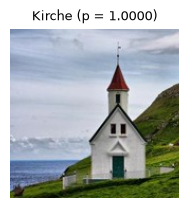

✅ 1.4 Modell ueber den Alias geladen, Kirche erkannt
⏹ mlflow-ui gestoppt


In [9]:
sys.path.insert(0, str(ARBEIT))                           # damit Python das Paket lab02 im Uebungs-Repo findet
from lab02.src.traeger import make_transform, predict     # dieselben Funktionen wie in Lab 2 und Lab 6

# TODO 1.4 (Loesung): modell = mlflow.pytorch.load_model("models:/traeger@champion").eval()
modell = mlflow.pytorch.load_model("models:/traeger@champion").eval()

tf = make_transform(train=False)                          # Vorverarbeitung wie in der Validierung
KLASSEN = [c["name"] for c in yaml.safe_load((ARBEIT / "models" / "traeger_v1.yaml").read_text())["classes"]]
klasse, p = predict(modell, tf, KLASSEN, ARBEIT / "lab07" / "kirche.JPEG")
print(f"Geladen: {type(modell).__name__} | Vorhersage: {klasse}")
for name, wert in zip(KLASSEN, p):
    print(f"   {name:18s} {wert:.4f}")
plt.figure(figsize=(2.2, 2.2)); plt.imshow(Image.open(ARBEIT / "lab07" / "kirche.JPEG")); plt.axis("off")
plt.title(f"{klasse} (p = {max(p):.4f})", fontsize=9); plt.show()
check("1.4 Modell ueber den Alias geladen, Kirche erkannt", lambda: klasse == "Kirche" and max(p) > 0.9)

stoppe("mlflow-ui")                                       # die Oberflaeche wird nicht mehr gebraucht

**Auswertung Aufgabe 1** (`DENKEN`)

1. Was passiert, wenn Sie die Zelle 1.3 ein zweites Mal ausführen? (Ausprobieren erlaubt.)

Es entsteht **Version 2** – aus demselben Run, mit denselben Dateien – und der Alias wandert auf Version 2.
Die Registry prüft nicht, ob ein Run schon registriert ist.

2. Ihr Dienst lädt `models:/traeger@champion`. Jemand registriert ein neues Modell als Version 2, setzt aber keinen Alias.
   Welche Version lädt der Dienst beim nächsten Start?

Weiter Version 1. Registrieren allein ändert nichts am
Betrieb; erst das Umhängen des Alias (Folie „Beispiel: Alias umhängen“, Fall C).

3. In `requirements.txt` des Modells stehen auch Pakete wie `transformers`. Braucht das Trägermodell sie? Woher kommen sie?

Nein. MLflow leitet die Liste aus den
Paketen ab, die beim Loggen in der Python-Sitzung geladen waren – in der Kursumgebung ziehen torchvision/Lightning einiges
nach. Für den Container pflegen wir deshalb eine eigene, kurze Liste (`requirements-service.txt`, Aufgabe 3). 

> 🎓 **Dozentenhinweis** · Besprechung ≈ 2 Min. Die drei Fragen von der Lab-Folie: Warum unterscheiden sich die Läufe? (Lernrate.) Was passiert
bei zweimal 1.3? (Version 2, Alias wandert.) Wo liegt das registrierte Modell? (`mlruns/models/traeger/…` enthält nur die
Verweise; die Dateien liegen im Artefaktordner des Runs – das hat die `PRINZIP`-Zelle gezeigt.) Wer schneller ist: Zusatz Z1
(Alias umhängen und zurückrollen).

## Aufgabe 2 · Service mit `/predict`

**In der Vorlesung live gezeigt auf Folie „Live: der Dienst“ · zu Hause ≈ 25 Min.** · Folien Abschnitt 4 · FastAPI 0.142.2 · uvicorn 0.54.0

Am Ende läuft ein Dienst auf Ihrem Rechner, Sie haben ihn mit einem Bild gefragt, Fehlerfälle ausgelöst und fünf grüne Tests
gesehen. **Dieser Block braucht kein Docker.**

| Teil | Inhalt | Art | Zeit |
|---|---|---|---|
| 2.1 | `app.py` vervollständigen | `LIVE` + `CODE` | 8 Min. |
| 2.2 | Starten und ausprobieren – und der Weg einer Anfrage von Hand | `CODE` + `PRINZIP` | 6 Min. |
| 2.3 | Fehlerfälle auslösen | `CODE` | 5 Min. |
| 2.4 | Tests ausführen und ergänzen | `CODE` | 6 Min. |

### 2.1 · `app.py` vervollständigen

`LIVE` + `CODE` · Folien „Code: app.py“ und „Schema für Anfrage und Antwort“. Der Dienst ist **eine Datei**.
Importe, das Laden des Modells und `/health` stehen schon da. Es fehlen:

- **2.1a – die beiden Schemas.** `Anfrage` hat ein Feld `image_b64` vom Typ `str`. `Antwort` hat drei Felder:
  `klasse` (`str`), `p` (`float`), `modell` (`str`). Schreibweise: je Feld eine Zeile `name: typ`.
- **2.1b – die Vorhersage.** `predict(model, tf, classes, bild)` aus Lab 2 gibt den Klassennamen und die Liste der fünf
  Wahrscheinlichkeiten zurück. Daraus die Antwort bauen: `Antwort(klasse=name, p=round(max(p), 4), modell=MODEL_URI)`.

Achten Sie auf die **Einrückung** (4 Leerzeichen je Ebene) – Python liest daran ab, was zur Klasse bzw. zur Funktion gehört.
Die Zelle schreibt die Datei nur; gestartet wird in 2.2.

> 🎓 **Dozentenhinweis** · 8 Min. am Beamer, langsam tippen und jede Zeile ansagen. Reihenfolge: erst 2.1a (zwei Klassen, vier Zeilen), dann
2.1b (zwei Zeilen). Dabei die drei Zonen der Datei zeigen: (1) läuft **einmal beim Start** (Modell laden – „nicht in die
Funktion schreiben, sonst lädt jede Anfrage 45 MB“), (2) Schema = Vertrag, (3) Endpunkte. `schreibe()` prüft die Syntax
sofort: Ein Einrückungsfehler erscheint als `IndentationError` direkt unter der Zelle, nicht erst beim Start des Dienstes.
Wer nicht fertig wird, übernimmt die Datei vom Beamer und macht ab 2.2 weiter.

In [10]:
abschnitt("Aufgabe 2")
schreibe("lab07/app.py", r"""
# lab07/app.py - der Dienst des Traegermodells
# Starten (aus dem Hauptordner des Repos):  uvicorn lab07.app:app
import base64, io, os

import mlflow.pytorch
import yaml
from fastapi import FastAPI, HTTPException
from PIL import Image
from pydantic import BaseModel

from lab02.src.traeger import make_transform, predict     # dieselbe Vorverarbeitung wie im Training - importiert, nicht abgetippt

# ---- laeuft EINMAL beim Start -------------------------------------------------------------------------------
MODEL_URI = os.getenv("MODEL_URI", "models:/traeger@champion")     # Umgebungsvariable MODEL_URI, sonst der Alias
model = mlflow.pytorch.load_model(MODEL_URI).eval()
tf = make_transform(train=False)
classes = [c["name"] for c in yaml.safe_load(open("models/traeger_v1.yaml"))["classes"]]


# ---- Schema: was hinein darf und was herauskommt ----------------------------------------------------------------
class Anfrage(BaseModel):
    # TODO 2.1a (Loesung): ein Feld: image_b64 vom Typ str
    image_b64: str                 # das Bild als Base64-Text


class Antwort(BaseModel):
    # TODO 2.1a (Loesung): drei Felder: klasse (str), p (float), modell (str)
    klasse: str                    # Name der vorhergesagten Klasse
    p: float                       # ihre Wahrscheinlichkeit (Softmax)
    modell: str                    # welches Modell geantwortet hat


app = FastAPI(title="Trägermodell-Service")


# ---- Endpunkte ---------------------------------------------------------------------------------------------------
@app.get("/health")
def health():
    return {"status": "ok", "modell": MODEL_URI}           # Lebenszeichen - benutzt das Modell nicht


@app.post("/predict", response_model=Antwort)
def vorhersage(a: Anfrage):                                # FastAPI prueft den JSON-Koerper gegen das Schema Anfrage
    try:
        bild = Image.open(io.BytesIO(base64.b64decode(a.image_b64))).convert("RGB")
    except Exception:
        raise HTTPException(422, "image_b64 ist kein lesbares Bild")
    # TODO 2.1b (Loesung): name, p = predict(model, tf, classes, bild) und return Antwort(klasse=name, p=round(max(p), 4), modell=MODEL_URI)
    name, p = predict(model, tf, classes, bild)            # Klassenname und Liste der 5 Wahrscheinlichkeiten
    return Antwort(klasse=name, p=round(max(p), 4), modell=MODEL_URI)
""")
check("2.1 app.py geschrieben, Schema und Endpunkt vorhanden",
      lambda: all(s in (ARBEIT / "lab07/app.py").read_text() for s in ("image_b64: str", "klasse: str", "predict(model, tf, classes, bild)")))

geschrieben: lab07/app.py (50 Zeilen)
✅ 2.1 app.py geschrieben, Schema und Endpunkt vorhanden


### 2.2 · Starten und ausprobieren

`CODE` (2 Zeilen) · Die erste Zelle startet den Dienst im Hintergrund – im Terminal hieße das
`uvicorn lab07.app:app` – und fragt `/health`.

**Im Browser ausprobieren:** Öffnen Sie die ausgegebene Adresse mit `/docs` am Ende. FastAPI hat aus Ihren Endpunkten und
Schemas eine interaktive Seite gebaut: `/predict` aufklappen → *Try it out* → in das Feld `image_b64` den Text aus der Datei
`results/kirche_b64.txt` einfügen (liegt neben diesem Notebook, in Jupyter per Doppelklick zu öffnen) → *Execute*.

**Im Notebook** (`CODE`): Bauen Sie die Anfrage selbst und schicken Sie sie ab:

- `anfrage = {"image_b64": b64_text}` – ein Dictionary mit genau dem Feld, das das Schema verlangt
- `status, antwort = frage(URL, "/predict", anfrage)`

**Erwartung:** Status `200`, `{"klasse": "Kirche", "p": 1.0, "modell": "models:/traeger@champion"}`.

In [11]:
PORT = freier_port(8000, 8001, 8002, 8003)                 # 8000 ist der Standard von uvicorn
URL = starte("dienst", f"uvicorn lab07.app:app --port {PORT}", PORT, pfad="/health")
print(f"\n👉 Im Browser oeffnen: {URL}/docs\n")
status, antwort = frage(URL, "/health")
check("2.2 /health antwortet mit status ok", lambda: status == 200 and antwort["status"] == "ok")

$ uvicorn lab07.app:app --port 8001   (im Hintergrund)
✅ dienst laeuft nach 3.3 s: http://127.0.0.1:8001/health   (Protokoll: results/dienst.log, beenden: stoppe("dienst"))

👉 Im Browser oeffnen: http://127.0.0.1:8001/docs

GET /health
   -> 200 in 2 ms: {"status": "ok", "modell": "models:/traeger@champion"}
✅ 2.2 /health antwortet mit status ok


In [12]:
# Das Bild als Base64-Text: Bytes der Datei -> Text aus 64 druckbaren Zeichen (JSON kann keine rohen Bytes transportieren)
bild_bytes = (ARBEIT / "lab07" / "kirche.JPEG").read_bytes()
b64_text = base64.b64encode(bild_bytes).decode()
(RESULTS / "kirche_b64.txt").write_text(b64_text)           # zum Kopieren in die Seite /docs
print(f"kirche.JPEG: {len(bild_bytes)} Byte -> {len(b64_text)} Zeichen Base64, Anfang: {b64_text[:24]}…\n")

# TODO 2.2 (Loesung): anfrage = {"image_b64": b64_text} und status, antwort = frage(URL, "/predict", anfrage)
anfrage = {"image_b64": b64_text}
status, antwort = frage(URL, "/predict", anfrage)

# Antwortzeit: 20-mal dieselbe Anfrage, mittlerer Wert (Median)
zeiten = []
for _ in range(20):
    t0 = time.perf_counter(); frage(URL, "/predict", anfrage, zeigen=False); zeiten.append((time.perf_counter() - t0) * 1000)
print(f"\nAntwortzeit je Anfrage (Median aus 20): {np.median(zeiten):.0f} ms")
check("2.2 /predict: Status 200, Klasse Kirche", lambda: status == 200 and antwort["klasse"] == "Kirche")
check("2.2 Antwort hat genau die Felder des Schemas", lambda: set(antwort) == {"klasse", "p", "modell"})

kirche.JPEG: 8829 Byte -> 11772 Zeichen Base64, Anfang: /9j/4AAQSkZJRgABAQAAAQAB…

POST /predict  {"image_b64": "/9j/4AAQSkZJRgABAQAAAQAB… (11772 Zeichen)"}
   -> 200 in 23 ms: {"klasse": "Kirche", "p": 1.0, "modell": "models:/traeger@champion"}

Antwortzeit je Anfrage (Median aus 20): 10 ms
✅ 2.2 /predict: Status 200, Klasse Kirche
✅ 2.2 Antwort hat genau die Felder des Schemas


#### 2.2 `PRINZIP` · Der Weg einer Anfrage – von Hand nachgegangen

`PRINZIP` + `CODE` (2 Zeilen) · Folie „Der Weg einer Anfrage“: Was ist zwischen `POST /predict` und der Antwort passiert?
Wir gehen die Stationen einzeln, mit einfachem Python und **ohne FastAPI**, und vergleichen am Ende mit der Antwort des Dienstes.

**Teil A – Base64 von Hand.** Je **3 Byte** (3 × 8 = 24 Bit) werden in **4 Zeichen** zu je 6 Bit zerlegt; jede 6-Bit-Zahl
(0…63) wählt ein Zeichen aus dem Alphabet `A–Z a–z 0–9 + /`. Daraus folgt die Länge:

$$\text{Zeichen} = 4 \cdot \left\lceil \frac{\text{Byte}}{3} \right\rceil \qquad\text{hier: } 4 \cdot \frac{8829}{3} = 11\,772$$

**Teil B – die Stationen.** JSON-Text → Dictionary → Schema prüfen → Base64 dekodieren → Bild öffnen → Vorverarbeitung →
Modell → Softmax → Antwort. **Lücke:** die Softmax-Funktion, die aus den fünf Ausgabewerten (Logits) $z_k$ Wahrscheinlichkeiten macht:

$$p_k = \frac{e^{z_k}}{\sum_j e^{z_j}}$$

**Erwartung:** Die ersten drei Byte jeder JPEG-Datei (`FF D8 FF`) ergeben `/9j/`; Ihre von Hand berechnete Antwort ist
dieselbe wie die des Dienstes.

In [32]:
# ---------- Teil A: Base64 fuer die ersten 3 Byte von Hand ----------------------------------------------------
ALPHABET = "ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz0123456789+/"      # 64 Zeichen: Index 0 ... 63
drei = bild_bytes[:3]
bits = "".join(f"{b:08b}" for b in drei)                    # jedes Byte als 8 Bit -> 24 Bit am Stueck
print("3 Byte:      ", " ".join(f"{b:02X}" for b in drei), " (so beginnt jede JPEG-Datei)")
print("24 Bit:      ", bits)
zeichen = ""
for i in range(0, 24, 6):                                   # in Vierergruppen zu je 6 Bit
    gruppe = bits[i:i + 6]
    zahl = int(gruppe, 2)                                   # 6 Bit als Zahl 0 ... 63
    zeichen += ALPHABET[zahl]
    print(f"   {gruppe} = {zahl:2d} -> '{ALPHABET[zahl]}'")
print("von Hand:    ", zeichen, "| Bibliothek:", base64.b64encode(drei).decode())
laenge = 4 * -(-len(bild_bytes) // 3)                       # 4 * aufgerundet(Byte / 3);  -(-a // b) rundet auf
print(f"Laenge:       4 * ceil({len(bild_bytes)} / 3) = {laenge} Zeichen (gemessen: {len(b64_text)})")

# ---------- Teil B: die Stationen des Dienstes -----------------------------------------------------------------
print("\nStation 1  JSON-Text kommt an:        ", (json_text := json.dumps(anfrage))[:44] + "…")
d = json.loads(json_text)                                   # Station 2: JSON-Text -> Dictionary
print("Station 2  als Dictionary, Schluessel:", list(d))
schema_ok = "image_b64" in d and isinstance(d["image_b64"], str)   # Station 3: Schema Anfrage - Feld da und ein Text?
print("Station 3  Schema erfuellt:           ", schema_ok, "(sonst: 422, das Modell wird gar nicht gefragt)")
roh = base64.b64decode(d["image_b64"])                      # Station 4: Base64 -> Bytes -> Bild
bild = Image.open(io.BytesIO(roh)).convert("RGB")
print("Station 4  Bild geoeffnet:            ", bild.size, bild.mode, f"({len(roh)} Byte)")
x = tf(bild).unsqueeze(0)                                   # Station 5: Vorverarbeitung wie im Training, plus Batch-Achse
print("Station 5  Tensor fuer das Modell:    ", tuple(x.shape), f"Wertebereich {x.min():.2f} … {x.max():.2f}")
with torch.no_grad():                                       # Station 6: Vorwaertsdurchlauf, ohne Gradienten
    logits = modell(x)[0].numpy()
print("Station 6  Logits:                    ", np.round(logits, 2))

def softmax(z):
    # TODO 2.2b (Loesung): e = np.exp(z - z.max()) und return e / e.sum()
    e = np.exp(z - z.max())                                 # e hoch z (z.max() abziehen aendert das Ergebnis nicht, vermeidet aber Ueberlauf)
    return e / e.sum()                                      # durch die Summe teilen -> Werte addieren sich zu 1

p_hand = softmax(logits)
k = int(p_hand.argmax())                                    # Index der groessten Wahrscheinlichkeit
antwort_hand = {"klasse": KLASSEN[k], "p": round(float(p_hand[k]), 4), "modell": "models:/traeger@champion"}
print("Station 7  Antwort von Hand:          ", antwort_hand)
print("           Antwort des Dienstes:      ", antwort)

check("2.2 PRINZIP: Base64 der ersten 3 Byte von Hand = /9j/", lambda: zeichen == "/9j/" == base64.b64encode(drei).decode())
check("2.2 PRINZIP: Laengenformel stimmt (11 772 Zeichen)", lambda: laenge == len(b64_text) == 11772)
check("2.2 PRINZIP: Softmax summiert zu 1", lambda: nah(softmax(np.array([1.0, 2.0, 3.0])).sum(), 1.0, 1e-9))
check("2.2 PRINZIP: von Hand dieselbe Klasse und Wahrscheinlichkeit wie der Dienst",
      lambda: antwort_hand["klasse"] == antwort["klasse"] and nah(antwort_hand["p"], antwort["p"], 2e-4))

3 Byte:       FF D8 FF  (so beginnt jede JPEG-Datei)
24 Bit:       111111111101100011111111
   111111 = 63 -> '/'
   111101 = 61 -> '9'
   100011 = 35 -> 'j'
   111111 = 63 -> '/'
von Hand:     /9j/ | Bibliothek: /9j/
Laenge:       4 * ceil(8829 / 3) = 11772 Zeichen (gemessen: 11772)

Station 1  JSON-Text kommt an:         {"image_b64": "/9j/4AAQSkZJRgABAQAAAQABAAD/2…
Station 2  als Dictionary, Schluessel: ['image_b64']
Station 3  Schema erfuellt:            True (sonst: 422, das Modell wird gar nicht gefragt)
Station 4  Bild geoeffnet:             (160, 160) RGB (8829 Byte)
Station 5  Tensor fuer das Modell:     (1, 3, 160, 160) Wertebereich -2.12 … 2.64
Station 6  Logits:                     [ -7.95  12.48 -10.08  -4.94  -4.72]
Station 7  Antwort von Hand:           {'klasse': 'Kirche', 'p': 1.0, 'modell': 'models:/traeger@champion'}
           Antwort des Dienstes:       {'klasse': 'Kirche', 'p': 1.0, 'modell': 'models:/traeger@champion'}
✅ 2.2 PRINZIP: Base64 der ersten 3 Byte von 

### 2.3 · Fehlerfälle auslösen

`CODE` (1 Zeile) + `DENKEN` · Folie „Beispiel: Eine Anfrage, eine Antwort“. Vier Anfragen, bei denen etwas nicht
stimmt – oder doch?

| Fall | Anfrage |
|---|---|
| a | `{"bild": "/9j/4AAQ…"}` – das richtige Bild, aber der Feldname ist falsch |
| b | `{"image_b64": "aGFsbG8="}` – gültiges Base64, dekodiert ergibt es den Text „hallo“ |
| c | ein gültiges Bild, das **keine** der fünf Klassen zeigt (hier: Rauschen) |
| d | ein gültiges Foto eines Fallschirms (`fallschirm_schwer.JPEG`) |

**Erst vorhersagen, dann schicken:** Tragen Sie in `tipp` für jeden Fall den Statuscode ein, den Sie erwarten (200 oder 422).
Die Zelle schickt dann alle vier Anfragen und stellt Ihren Tipp neben das Ergebnis.

--- Fall a
POST /predict  {"bild": "/9j/4AAQSkZJRgABAQAAAQAB… (11772 Zeichen)"}
   -> 422 in 2 ms: {"detail": [{"type": "missing", "loc": ["body", "image_b64"], "msg": "Field required", "input": {"bild": "/9j/4AAQSkZJRgABAQAAAQAB… (11772 Zeichen)"}}]}
--- Fall b
POST /predict  {"image_b64": "aGFsbG8="}
   -> 422 in 2 ms: {"detail": "image_b64 ist kein lesbares Bild"}
--- Fall c
POST /predict  {"image_b64": "/9j/4AAQSkZJRgABAQAAAQAB… (21328 Zeichen)"}
   -> 200 in 18 ms: {"klasse": "Fallschirm", "p": 0.5767, "modell": "models:/traeger@champion"}
--- Fall d
POST /predict  {"image_b64": "/9j/4AAQSkZJRgABAQAAAQAB… (10512 Zeichen)"}
   -> 200 in 11 ms: {"klasse": "Kirche", "p": 0.7337, "modell": "models:/traeger@champion"}


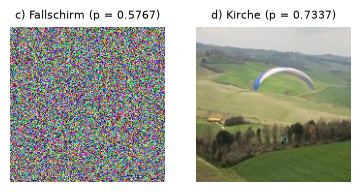

,Ihr Tipp,Statuscode,Antwort
a,422,422,"{""detail"": [{""type"": ""missing"", ""loc"": [""body""..."
b,422,422,"{""detail"": ""image_b64 ist kein lesbares Bild""}"
c,200,200,"{""klasse"": ""Fallschirm"", ""p"": 0.5767, ""modell""..."
d,200,200,"{""klasse"": ""Kirche"", ""p"": 0.7337, ""modell"": ""m..."


✅ 2.3 Statuscodes: a 422, b 422, c 200, d 200
✅ 2.3 Ihr Tipp stimmt mit dem Ergebnis ueberein


In [13]:
# TODO 2.3 (Loesung): Ihr Tipp, z. B. tipp = {"a": 200, "b": 200, "c": 422, "d": 422} - welche Statuscodes erwarten Sie?
tipp = {"a": 422, "b": 422, "c": 200, "d": 200}

def als_b64(bild):
    """PIL-Bild oder Pfad -> Base64-Text (als JPEG)."""
    if isinstance(bild, Image.Image):
        puffer = io.BytesIO(); bild.save(puffer, format="JPEG"); return base64.b64encode(puffer.getvalue()).decode()
    return base64.b64encode(Path(bild).read_bytes()).decode()

rauschen = Image.fromarray(np.random.default_rng(0).integers(0, 256, (160, 160, 3), dtype=np.uint8))   # zufaellige Pixel
faelle = {"a": {"bild": b64_text},
          "b": {"image_b64": "aGFsbG8="},
          "c": {"image_b64": als_b64(rauschen)},
          "d": {"image_b64": als_b64(ARBEIT / "lab07" / "fallschirm_schwer.JPEG")}}
ergebnis = {}
for fall, daten in faelle.items():
    print(f"--- Fall {fall}")
    ergebnis[fall] = frage(URL, "/predict", daten)

fig, achsen = plt.subplots(1, 2, figsize=(4.4, 2.3))
for ax, bild, titel in zip(achsen, (rauschen, Image.open(ARBEIT / "lab07" / "fallschirm_schwer.JPEG")),
                           (f"c) {ergebnis['c'][1].get('klasse')} (p = {ergebnis['c'][1].get('p')})",
                            f"d) {ergebnis['d'][1].get('klasse')} (p = {ergebnis['d'][1].get('p')})")):
    ax.imshow(bild); ax.axis("off"); ax.set_title(titel, fontsize=8)
plt.show()
display(pd.DataFrame({"Ihr Tipp": tipp, "Statuscode": {f: e[0] for f, e in ergebnis.items()},
                      "Antwort": {f: json.dumps(kurz(e[1], 70), ensure_ascii=False)[:95] for f, e in ergebnis.items()}}))
check("2.3 Statuscodes: a 422, b 422, c 200, d 200", lambda: [ergebnis[f][0] for f in "abcd"] == [422, 422, 200, 200])
check("2.3 Ihr Tipp stimmt mit dem Ergebnis ueberein", lambda: all(tipp[f] == ergebnis[f][0] for f in "abcd"),
      "kein Problem - genau dafuer ist die Aufgabe da; Auswertung lesen")

**Auswertung 2.3** (`DENKEN`)

1. Fall a und b enden beide mit 422 – aber an **verschiedenen Stationen**. Welche Station lehnt jeweils ab? Woran erkennen
   Sie das in der Antwort?

a) **Station 3 (Schema)** – FastAPI/Pydantic antwortet selbst, bevor unsere Funktion läuft:
`{"detail": [{"type": "missing", "loc": ["body", "image_b64"], "msg": "Field required", …}]}`. 

b) **Station 4 (Bild öffnen)**
– das Schema ist zufrieden (es ist ein Text), erst `Image.open` scheitert; die Antwort trägt **unsere** Meldung
`"image_b64 ist kein lesbares Bild"`.

2. Fall c und d bekommen Status 200. Ist die Antwort deshalb richtig? Was bedeutet der Statuscode 200 – und was nicht?

Nein. 200 heißt nur: Die Anfrage wurde verarbeitet. In c antwortet das Modell mit
einer der fünf Klassen, weil es nichts anderes kann; in d zeigt das Bild einen Fallschirm, die Antwort lautet „Kirche“
(p ≈ 0,73) – einer der 8 Validierungsfehler.

3. Was könnte ein Dienst bei Fall c idealerweise tun? Nennen Sie eine Maßnahme im Dienst und eine außerhalb.

Im Dienst: Schwelle für `p`, darunter „unsicher“ antworten oder ein Feld
`sicher: false` mitgeben. Außerhalb: Eingaben und Wahrscheinlichkeiten überwachen (Monitoring & Drift, nächste Woche),
Stichproben von Menschen prüfen lassen. Achtung: Softmax-Werte sind kein verlässliches Maß für „kenne ich nicht“ – das
Rauschbild bekommt p ≈ 0,58 für „Fallschirm“, das falsch erkannte echte Foto in d) sogar p ≈ 0,73.

> 🎓 **Dozentenhinweis** · Die Diskussion zu c/d ist der wichtigste Teil der Aufgabe (Missverständnis: „200 = richtige Vorhersage“). Fall d
weicht von der Folie ab (dort ist c ein Hundefoto und es gibt kein d): Das schwierige Fallschirm-Bild macht denselben Punkt
mit einem Bild **aus** der Zielverteilung – technisch und fachlich eine gültige Anfrage, trotzdem falsch beantwortet.
Kontrollwerte Lösungslauf: c) Fallschirm, p = 0.5767 · d) Kirche, p = 0.7337.

### 2.4 · Tests ausführen und ergänzen

`CODE` · Folie „Code: test_app.py“. Die erste Zelle schreibt die vier Tests von der Folie und führt sie aus:

```
python -m pytest lab07 -q
```

pytest sucht im Ordner `lab07` alle Dateien `test_*.py`, ruft darin jede Funktion auf, deren Name mit `test_` beginnt, und
meldet, ob alle `assert`-Zeilen wahr waren. Der `TestClient` ruft die Anwendung **direkt** auf – ohne Server, ohne Port.

**Ihre Aufgabe (zweite Zelle):** Schreiben Sie einen fünften Test `test_fallschirm`: Das Bild `lab07/fallschirm.JPEG` muss
Status 200 und die Klasse `"Fallschirm"` ergeben. Orientieren Sie sich an `test_kirche`.

**Erwartung:** erst `4 passed`, dann `5 passed`.

In [14]:
TESTS = r"""
# lab07/test_app.py - Tests fuer den Dienst. Ausfuehren (aus dem Hauptordner):  python -m pytest lab07 -q
import base64
from fastapi.testclient import TestClient
from lab07.app import app                      # importiert den Dienst - dabei wird das Modell geladen

client = TestClient(app)                       # ruft die Anwendung direkt auf, ohne Server


def b64(pfad):
    return base64.b64encode(open(pfad, "rb").read()).decode()


def test_health():
    r = client.get("/health")
    assert r.json()["status"] == "ok"


def test_kirche():                             # ein gutes Bild -> 200, richtige Klasse, p zwischen 0 und 1
    r = client.post("/predict", json={"image_b64": b64("lab07/kirche.JPEG")})
    assert r.status_code == 200
    assert r.json()["klasse"] == "Kirche"
    assert 0 <= r.json()["p"] <= 1


def test_kein_bild():                          # "hallo" als Base64 -> 422 von unserer Fehlerbehandlung
    r = client.post("/predict", json={"image_b64": "aGFsbG8="})
    assert r.status_code == 422


def test_feld_fehlt():                         # leere Anfrage -> 422 vom Schema
    r = client.post("/predict", json={})
    assert r.status_code == 422
"""
schreibe("lab07/test_app.py", TESTS)
t = run("python -m pytest lab07 -q")
check("2.4 Vier Tests gruen", lambda: "4 passed" in t.ausgabe)

geschrieben: lab07/test_app.py (32 Zeilen)
$ python -m pytest lab07 -q
   ....                                                                     [100%]
   4 passed in 2.84s
✅ 2.4 Vier Tests gruen


In [15]:
schreibe("lab07/test_app.py", TESTS + r"""

def test_fallschirm():                         # Ihr Test: fallschirm.JPEG -> 200 und Klasse "Fallschirm"
    # TODO 2.4 (Loesung): wie test_kirche: client.post(...) mit b64("lab07/fallschirm.JPEG"), dann zwei assert-Zeilen
    r = client.post("/predict", json={"image_b64": b64("lab07/fallschirm.JPEG")})
    assert r.status_code == 200
    assert r.json()["klasse"] == "Fallschirm"
""")
t = run("python -m pytest lab07 -q", erwarte_fehler=True)
check("2.4 Fuenf Tests gruen", lambda: "5 passed" in t.ausgabe, "Ausgabe von pytest lesen: Welche assert-Zeile ist falsch?")

run("git add lab07"); run('git commit -q -m "Lab 7: Dienst und Tests"', erwarte_fehler=True)
stoppe("dienst")                                          # in Aufgabe 3 starten wir ihn mit anderem MODEL_URI neu

geschrieben: lab07/test_app.py (39 Zeilen)
$ python -m pytest lab07 -q
   .....                                                                    [100%]
   5 passed in 2.81s
✅ 2.4 Fuenf Tests gruen
$ git add lab07
$ git commit -q -m "Lab 7: Dienst und Tests"
   On branch main
   Untracked files:
     (use "git add <file>..." to include in what will be committed)
   	lab08/
   
   nothing added to commit but untracked files present (use "git add" to track)
   (Fehler war hier erwartet bzw. erlaubt – Meldung lesen!)
⏹ dienst gestoppt


**Auswertung Aufgabe 2** (`DENKEN`)

1. Die Tests liefen, während der Dienst aus 2.2 noch lief – sie wären aber auch **ohne** ihn gelaufen. Warum?

Der `TestClient` importiert das Objekt `app` und ruft die Endpunkt-Funktionen direkt im selben Prozess auf –
kein Netzwerk, kein Port, kein uvicorn. Deshalb laufen dieselben Tests später unverändert in der CI.

2. Was müssten Sie ändern, damit der Dienst Version 2 statt `champion` lädt? (Tipp: erste Zeile unter „läuft einmal beim Start“.)

Keinen Code: nur die Umgebungsvariable setzen, z. B. `MODEL_URI=models:/traeger/2` (macOS/Linux: `export`, PowerShell: `$env:MODEL_URI = …`) und den Dienst neu starten.

3. `test_kirche` prüft **ein** Bild. Sagt ein grüner Test etwas über die Qualität des Modells? Was prüft er eigentlich?

Kaum. Er prüft die **Verdrahtung**: Dienst startet, Modell lädt, Vorverarbeitung und
Klassenreihenfolge passen so weit, dass ein eindeutiges Bild richtig herauskommt. Für die Qualität bräuchte es einen
Modelltest mit Schwelle auf dem ganzen Validierungssplit (Folie „ML braucht mehr Tests“) – ein Baustein für das Capstone.

> 🎓 **Dozentenhinweis** · Die drei Fragen der Lab-Folie; bei (3) den Bogen zu „Drei Pyramiden statt einer“ schlagen. Kontrollwert:
`5 passed` in ≈ 5 s (davon ≈ 4 s Import von torch/mlflow und Laden des Modells). pytest zeigt in der Kursumgebung keine
Warnungen, weil `run()` `PYTHONWARNINGS=ignore` setzt; im Terminal erscheinen drei Deprecation-Warnungen aus Starlette und
MLflow – harmlos.

## Aufgabe 3 · Dockerfile und Container

**In der Vorlesung live gezeigt auf Folie „Live: vom Dockerfile zum Container“ · zu Hause ≈ 25 Min.** · Folien Abschnitt 5 · Docker Docs

Am Ende haben **alle** ein vollständiges Dockerfile und können vorhersagen, welche Schichten Docker nach einer Änderung neu
baut. Wer Docker (oder Podman) hat, hat außerdem den Dienst im Container aufgerufen und den Cache beobachtet.

| Teil | Inhalt | Art | Zeit | ohne Docker? |
|---|---|---|---|---|
| 3.1 | Modell exportieren | `LIVE` | 5 Min. | ✅ |
| 3.2 | Dockerfile vervollständigen – und den Build-Kontext von Hand bestimmen | `CODE` + `PRINZIP` | 7 Min. | ✅ |
| 3.3 | Bauen und starten | `CODE` | 8 Min. | Fallback-Kette |
| 3.4 | Cache beobachten – erst von Hand, dann mit Docker | `PRINZIP` + `CODE` | 5 Min. | ✅ (Teil von Hand) |

**Wenn Docker bei Ihnen nicht läuft** (Folie „Wenn Docker nicht läuft“): 3.1, 3.2 und den `PRINZIP`-Teil von 3.4 bearbeiten
Sie ganz normal. Gebaut wird Ihr Dockerfile dann (1) mit Podman/Rancher Desktop, (2) in Aufgabe 4 auf einem Rechner von
GitHub oder (3) von einem Teammitglied. **Bewertet werden Dockerfile und CI-Log – nicht der lokale Build.**

### 3.1 · Modell exportieren

`LIVE` · Im Container gibt es kein `mlruns/` und keine Registry. Deshalb legen wir **vor dem Bauen** genau die
Version, an der `champion` hängt, als Ordner neben den Code:

```python
mlflow.artifacts.download_artifacts("models:/traeger@champion", dst_path="lab07/model")
```

Danach starten wir den Dienst einmal mit der Umgebungsvariable `MODEL_URI=lab07/model` – **derselbe Code**, aber das Modell
kommt jetzt aus dem Ordner. Der Alias entscheidet also **beim Export**, nicht zur Laufzeit: Das Image enthält genau ein
Modell, unveränderlich.

**Erwartung:** `lab07/model/` mit `MLmodel`, `requirements.txt` und `data/model.pth` (44,8 MB, bitgleich mit der Datei im
Run); `/health` meldet `"modell": "lab07/model"`.

> 🎓 **Dozentenhinweis** · 5 Min. am Beamer. Kernaussage: **Registry zur Entwicklungszeit, Ordner zur Laufzeit.** Der Container soll ohne
Tracking-Server starten können. Auf `/health` zeigen: vorher `models:/traeger@champion`, jetzt `lab07/model` – ohne eine
Zeile Code zu ändern (Umgebungsvariable). `lab07/model/` steht im Übungs-Repo in `.gitignore`; ins Service-Repo (Aufgabe 4)
kommt der Ordner mit, damit die CI ihn hat. Frage ans Plenum: „Was passiert, wenn morgen jemand den Alias umhängt?“ → Nichts,
bis neu exportiert und gebaut wird – genau das soll später die CI automatisch tun (Continuous Delivery).

In [16]:
abschnitt("Aufgabe 3")
EXPORT = ARBEIT / "lab07" / "model"
if EXPORT.exists():
    loesche(EXPORT)                                          # alten Export entfernen, damit keine Reste bleiben
mlflow.artifacts.download_artifacts("models:/traeger@champion", dst_path=str(EXPORT))

print("lab07/model/ (Export der Version, an der champion haengt):")
for p in sorted(EXPORT.rglob("*")):
    if p.is_file():
        print(f"   {p.relative_to(EXPORT).as_posix():28s} {p.stat().st_size:>10,d} Byte".replace(",", " "))
def md5_datei(pfad):
    return hashlib.md5(Path(pfad).read_bytes()).hexdigest()
check("3.1 Export vollstaendig (MLmodel, data/model.pth)", lambda: (EXPORT / "MLmodel").exists() and (EXPORT / "data/model.pth").exists())
check("3.1 model.pth im Export ist bitgleich mit der Datei im Run (gleiche MD5)",
      lambda: md5_datei(EXPORT / "data/model.pth") == md5_datei(modell_ordner / "data/model.pth"))

# Derselbe Dienst, aber das Modell kommt aus dem Ordner statt aus der Registry
PORT = freier_port(8000, 8001, 8002, 8003)
URL = starte("dienst", f"uvicorn lab07.app:app --port {PORT}", PORT, pfad="/health", umgebung={"MODEL_URI": "lab07/model"})
status, antwort = frage(URL, "/health")
status_p, antwort_p = frage(URL, "/predict", anfrage)
stoppe("dienst")
check("3.1 Dienst laedt aus dem Ordner: /health meldet modell = lab07/model", lambda: antwort["modell"] == "lab07/model")
check("3.1 ... und antwortet wie vorher (Kirche)", lambda: status_p == 200 and antwort_p["klasse"] == "Kirche")

lab07/model/ (Export der Version, an der champion haengt):
   MLmodel                             548 Byte
   conda.yaml                          455 Byte
   data/model.pth               44 800 075 Byte
   data/pickle_module_info.txt          28 Byte
   python_env.yaml                     107 Byte
   registered_model_meta                37 Byte
   requirements.txt                    297 Byte
✅ 3.1 Export vollstaendig (MLmodel, data/model.pth)
✅ 3.1 model.pth im Export ist bitgleich mit der Datei im Run (gleiche MD5)
$ MODEL_URI=lab07/model uvicorn lab07.app:app --port 8001   (im Hintergrund)
✅ dienst laeuft nach 3.7 s: http://127.0.0.1:8001/health   (Protokoll: results/dienst.log, beenden: stoppe("dienst"))
GET /health
   -> 200 in 2 ms: {"status": "ok", "modell": "lab07/model"}
POST /predict  {"image_b64": "/9j/4AAQSkZJRgABAQAAAQAB… (11772 Zeichen)"}
   -> 200 in 28 ms: {"klasse": "Kirche", "p": 1.0, "modell": "lab07/model"}
⏹ dienst gestoppt
✅ 3.1 Dienst laedt aus dem Ordner: /health

### 3.2 · Dockerfile vervollständigen

`CODE` · Folie „Code: Dockerfile des Service“. Das Dockerfile ist das Rezept für das Image. Grundsystem, Pakete,
`ENV` und `EXPOSE` stehen da. Es fehlen:

- **3.2a – vier `COPY`-Zeilen**, die Code, Modellbeschreibung und Modell ins Image legen. Schreibweise:
  `COPY <Pfad im Repo> <Pfad im Image>` – hier jeweils derselbe Pfad. Gebraucht werden `lab02/src`, `lab07/app.py`,
  `models/traeger_v1.yaml` und `lab07/model`. **Reihenfolge wie aufgezählt** (warum, zeigt 3.4).
- **3.2b – der Startbefehl** `CMD` als Liste in eckigen Klammern: `uvicorn` soll `lab07.app:app` starten, mit
  `--host 0.0.0.0` (Anfragen von außerhalb des Containers annehmen) und `--port 8000`.
  Schreibweise: `CMD ["programm", "argument1", "argument2", …]`

Im Dockerfile ist eine Lücke nur ein Kommentar `# TODO …` (hier gibt es kein `raise`) – ersetzen Sie **die Kommentarzeile
selbst** durch Ihre Zeilen. Solange sie noch dasteht, hält `schreibe()` mit `NotImplementedError: TODO 3.2a …` an.
Die Zelle prüft danach die Anweisungen, **ohne** Docker zu brauchen.

In [17]:
schreibe("lab07/Dockerfile", r"""
# lab07/Dockerfile - Bauplan fuer das Image des Dienstes
# Bauen (aus dem Hauptordner des Repos):  docker build -t traeger-service -f lab07/Dockerfile .

# Grundsystem: schlankes Debian mit Python 3.12
FROM python:3.12-slim
# Arbeitsordner im Image - alle folgenden Pfade beziehen sich darauf
WORKDIR /app

# PyTorch als CPU-Variante (das Standardpaket bringt unter Linux die CUDA-Bibliotheken mit und ist um ein Vielfaches groesser)
RUN pip install --no-cache-dir torch==2.8.0 torchvision==0.23.0 \
    --index-url https://download.pytorch.org/whl/cpu

# Die uebrigen Pakete: erst nur die Liste kopieren, dann installieren
COPY lab07/requirements-service.txt .
RUN pip install --no-cache-dir -r requirements-service.txt

# Code, Modellbeschreibung und Modell - erst jetzt, NACH den Paketen
# TODO 3.2a (Loesung): vier COPY-Zeilen: lab02/src, lab07/app.py, models/traeger_v1.yaml, lab07/model (jeweils gleicher Pfad im Image)
COPY lab02/src lab02/src
COPY lab07/app.py lab07/app.py
COPY models/traeger_v1.yaml models/traeger_v1.yaml
COPY lab07/model lab07/model

# Der Dienst laedt im Container aus dem Ordner statt ueber den Alias
ENV MODEL_URI=lab07/model
EXPOSE 8000
# TODO 3.2b (Loesung): CMD als Liste: uvicorn startet lab07.app:app mit --host 0.0.0.0 und --port 8000
CMD ["uvicorn", "lab07.app:app", "--host", "0.0.0.0", "--port", "8000"]
""")

def dockerfile_schritte(text):
    """Dockerfile -> Liste (ANWEISUNG, Argumente). Kommentare fallen weg, Fortsetzungszeilen (Backslash am Ende) werden zusammengefuegt."""
    schritte, puffer = [], ""
    for zeile in text.splitlines():
        z = zeile.strip()
        if not z or z.startswith("#"):
            continue
        if z.endswith("\\"):                                 # Anweisung geht in der naechsten Zeile weiter
            puffer += z[:-1].strip() + " "; continue
        anweisung, _, argumente = (puffer + z).strip().partition(" ")
        schritte.append((anweisung.upper(), argumente.strip())); puffer = ""
    return schritte

SCHRITTE = dockerfile_schritte((ARBEIT / "lab07/Dockerfile").read_text())
for nr, (anweisung, argumente) in enumerate(SCHRITTE, 1):
    print(f"{nr:2d}  {anweisung:8s} {argumente[:100]}")
kopiert = [arg.split()[0] for anw, arg in SCHRITTE if anw == "COPY"]
def startbefehl():
    """Argumente von CMD als Liste (CMD muss in der Listen-Schreibweise mit eckigen Klammern stehen)."""
    return json.loads(next(arg for anw, arg in SCHRITTE if anw == "CMD"))
check("3.2 COPY: Paketliste, lab02/src, lab07/app.py, models/traeger_v1.yaml, lab07/model",
      lambda: kopiert == ["lab07/requirements-service.txt", "lab02/src", "lab07/app.py", "models/traeger_v1.yaml", "lab07/model"],
      "Reihenfolge beachten; Paketliste zuerst")
check("3.2 Jede COPY-Quelle existiert im Uebungs-Repo", lambda: all((ARBEIT / q).exists() for q in kopiert))
check("3.2 CMD startet uvicorn lab07.app:app mit --host 0.0.0.0 --port 8000",
      lambda: startbefehl()[:2] == ["uvicorn", "lab07.app:app"] and "0.0.0.0" in startbefehl() and "8000" in startbefehl(),
      'Schreibweise: CMD ["uvicorn", "lab07.app:app", "--host", "0.0.0.0", "--port", "8000"]')
run("git add lab07/Dockerfile")
_ = run('git commit -q -m "Lab 7: Dockerfile"', erwarte_fehler=True)

geschrieben: lab07/Dockerfile (28 Zeilen)
 1  FROM     python:3.12-slim
 2  WORKDIR  /app
 3  RUN      pip install --no-cache-dir torch==2.8.0 torchvision==0.23.0 --index-url https://download.pytorch.org
 4  COPY     lab07/requirements-service.txt .
 5  RUN      pip install --no-cache-dir -r requirements-service.txt
 6  COPY     lab02/src lab02/src
 7  COPY     lab07/app.py lab07/app.py
 8  COPY     models/traeger_v1.yaml models/traeger_v1.yaml
 9  COPY     lab07/model lab07/model
10  ENV      MODEL_URI=lab07/model
11  EXPOSE   8000
12  CMD      ["uvicorn", "lab07.app:app", "--host", "0.0.0.0", "--port", "8000"]
✅ 3.2 COPY: Paketliste, lab02/src, lab07/app.py, models/traeger_v1.yaml, lab07/model
✅ 3.2 Jede COPY-Quelle existiert im Uebungs-Repo
✅ 3.2 CMD startet uvicorn lab07.app:app mit --host 0.0.0.0 --port 8000
$ git add lab07/Dockerfile
$ git commit -q -m "Lab 7: Dockerfile"
   On branch main
   Untracked files:
     (use "git add <file>..." to include in what will be committed)
   

#### 3.2 `PRINZIP` · Der Build-Kontext – von Hand bestimmt

`PRINZIP` · Der Punkt am Ende von `docker build … .` ist der **Build-Kontext**: Diesen Ordner schickt Docker vor dem Bauen
komplett an den Docker-Dienst – nur daraus kann `COPY` Dateien nehmen. Ihr Übungs-Repo enthält aber auch 3 000 Bilder, den
DVC-Cache, `.git/` und `mlruns/`. Die Datei `.dockerignore` dreht den Spieß um:

```
*                      zuerst alles ausschließen
!lab02/src             dann einzeln wieder erlauben (das Ausrufezeichen heißt „doch“)
!lab07/app.py
…
**/__pycache__         … außer Zwischendateien von Python
```

Die Zelle wendet diese Regeln mit einer einfachen Schleife auf alle Dateien des Übungs-Repos an und zählt.
**Erwartung:** Vom ganzen Ordner (mehrere hundert MB) bleiben ≈ 45 MB – fast nur das Modell.

In [38]:
regeln = [z.strip() for z in (ARBEIT / ".dockerignore").read_text().splitlines() if z.strip() and not z.startswith("#")]
print(".dockerignore:", regeln)
erlaubt = [r[1:] for r in regeln if r.startswith("!")]       # Regeln mit "!" = Ausnahmen vom "alles ausschliessen"

def im_kontext(rel):
    """rel = Pfad relativ zum Hauptordner, mit '/'. True, wenn die Datei zum Docker-Dienst geschickt wird."""
    if "__pycache__" in rel.split("/"):                      # Regel **/__pycache__
        return False
    return any(rel == e or rel.startswith(e + "/") for e in erlaubt)

alles, kontext, dateien_kontext = 0, 0, []
for p in ARBEIT.rglob("*"):                                  # jede Datei im Uebungs-Repo, auch in .git/ und .dvc/
    if p.is_file():
        rel = p.relative_to(ARBEIT).as_posix()
        alles += p.stat().st_size
        if im_kontext(rel):
            kontext += p.stat().st_size; dateien_kontext.append(rel)
print(f"\nGanzer Ordner: {alles / 1e6:7.1f} MB")
print(f"Build-Kontext: {kontext / 1e6:7.1f} MB in {len(dateien_kontext)} Dateien:")
for rel in sorted(dateien_kontext):
    print("   ", rel)
check("3.2 PRINZIP: Build-Kontext unter 60 MB und ohne Bilder, .git, mlruns",
      lambda: kontext < 60e6 and not any(r.startswith(("data/", ".git/", "mlruns/", ".dvc/")) for r in dateien_kontext))
check("3.2 PRINZIP: alles, was das Dockerfile kopiert, ist im Kontext",
      lambda: all(any(d == q or d.startswith(q + "/") for d in dateien_kontext) for q in kopiert))

.dockerignore: ['*', '!lab02/src', '!lab07/app.py', '!lab07/model', '!lab07/requirements-service.txt', '!models/traeger_v1.yaml', '**/__pycache__']

Ganzer Ordner:   458.2 MB
Build-Kontext:    44.8 MB in 12 Dateien:
    lab02/src/__init__.py
    lab02/src/traeger.py
    lab07/app.py
    lab07/model/MLmodel
    lab07/model/conda.yaml
    lab07/model/data/model.pth
    lab07/model/data/pickle_module_info.txt
    lab07/model/python_env.yaml
    lab07/model/registered_model_meta
    lab07/model/requirements.txt
    lab07/requirements-service.txt
    models/traeger_v1.yaml
✅ 3.2 PRINZIP: Build-Kontext unter 60 MB und ohne Bilder, .git, mlruns
✅ 3.2 PRINZIP: alles, was das Dockerfile kopiert, ist im Kontext


### 3.3 · Bauen und starten

`CODE` (1 Zeile) · **nur mit Docker oder Podman** – sonst meldet die Zelle „übersprungen“ und Sie gehen zu 3.4.

Die Zelle baut das Image (`docker build -t traeger-service -f lab07/Dockerfile .`). **Der erste Build lädt das Grundsystem
und PyTorch herunter – je nach Netz dauert das einige Minuten.** Lesen Sie währenddessen den Text zu 3.4.

**Ihre Lücke:** den Container starten. Der Befehl hat vier Teile, die Sie kennen sollten:

```
docker run -d --rm --name traeger-service -p <Port außen>:8000 traeger-service
           │   │    │                      │
           │   │    │                      └─ Port 8000 im Container mit einem Port Ihres Rechners verbinden
           │   │    └─ Name des Containers (zum Stoppen und für docker logs)
           │   └─ Container nach dem Stoppen wieder löschen
           └─ im Hintergrund starten (detached)
```

Im Notebook: `run(f"{DOCKER} run -d --rm --name traeger-service -p {PORT_C}:8000 traeger-service")` – `DOCKER` ist `docker`
oder `podman`, `PORT_C` ein freier Port auf Ihrem Rechner.

**Erwartung:** `/health` antwortet aus dem Container mit `"modell": "lab07/model"`, `/predict` erkennt die Kirche.

In [18]:
KEIN_DOCKER = ("⏭ uebersprungen: Auf diesem Rechner laeuft weder Docker noch Podman.\n"
               "   Fallback-Kette: (1) Podman Desktop / Rancher Desktop installieren, (2) Build in GitHub Actions (Aufgabe 4),\n"
               "   (3) ein Teammitglied baut. Ihr Dockerfile aus 3.2 zaehlt trotzdem - weiter mit 3.4 (Teil von Hand).")
BAU_NUR = r"^#\d+ (\[\d+/\d+\]|CACHED|ERROR)|^(STEP \d+|--> Using cache)"       # nur die Zeilen der Bauschritte zeigen

OHNE_CACHE = os.environ.get("AKE_LAB07_OHNE_CACHE") == "1"    # True: beim ersten Build nichts aus dem Cache nehmen (volle Bauzeit messen)

def baue(ordner=None, ohne_cache=False):
    """Image traeger-service bauen. Rueckgabe: (Ergebnis von run, Anzahl der Schritte aus dem Cache)."""
    erg = run([DOCKER, "build", *(["--no-cache"] if ohne_cache else []), "-t", "traeger-service", "-f", "lab07/Dockerfile", "."], cwd=ordner, nur=BAU_NUR,
              erwarte_fehler=True, umgebung={"BUILDKIT_PROGRESS": "plain"})      # plain = eine Zeile je Schritt
    if not erg.ok and "failed to prepare extraction snapshot" in erg.ausgabe:
        # bekannte Macke von Docker Desktop (Image-Speicher raeumt gerade auf) - ein zweiter Versuch genuegt
        print("   Docker meldet einen voruebergehenden Fehler im Image-Speicher – zweiter Versuch ...")
        return baue(ordner, ohne_cache)
    cached = len(re.findall(r"^#\d+ CACHED|^--> Using cache", erg.ausgabe, re.M))
    print(f"   {'✅ Build fertig' if erg.ok else '❌ Build fehlgeschlagen'} in {erg.sekunden:.0f} s, {cached} Schritte aus dem Cache")
    return erg, cached

URL_C = None
if not DOCKER_OK:
    print(KEIN_DOCKER)
else:
    bau1, _ = baue(ohne_cache=OHNE_CACHE)
    if bau1.ok:
        run([DOCKER, "rm", "-f", "traeger-service"], zeigen=False, erwarte_fehler=True)   # alten Container entfernen, falls da
        PORT_C = freier_port(8000, 8001, 8002, 8003)
        print()
        # TODO 3.3 (Loesung): run(f"{DOCKER} run -d --rm --name traeger-service -p {PORT_C}:8000 traeger-service")
        run(f"{DOCKER} run -d --rm --name traeger-service -p {PORT_C}:8000 traeger-service")
        URL_C = f"http://127.0.0.1:{PORT_C}"
        gewartet = warte_auf(URL_C + "/health", 90)
        print(f"Container antwortet nach {gewartet:.1f} s\n" if gewartet is not None else "❌ Container antwortet nicht – docker logs traeger-service lesen\n")
        status_c, antwort_c = frage(URL_C, "/health")
        status_cp, antwort_cp = frage(URL_C, "/predict", anfrage)
        print()
        run([DOCKER, "ps", "--filter", "name=traeger-service"])
        run([DOCKER, "logs", "--tail", "3", "traeger-service"])
        GROESSE = run([DOCKER, "image", "ls", "traeger-service", "--format", "{{.Size}}"], zeigen=False).ausgabe.strip()
        print(f"\nImage traeger-service: {GROESSE}   |   👉 im Browser: {URL_C}/docs  (der Container laeuft weiter bis zum Ende von 3.4)")
        check("3.3 Container antwortet auf /health mit modell = lab07/model", lambda: status_c == 200 and antwort_c["modell"] == "lab07/model")
        check("3.3 /predict im Container: Kirche", lambda: status_cp == 200 and antwort_cp["klasse"] == "Kirche")

$ BUILDKIT_PROGRESS=plain docker build -t traeger-service -f lab07/Dockerfile .
   #5 [1/9] FROM docker.io/library/python:3.12-slim@sha256:5e2bdb1b0d542d5039cffb8181c65930093949194a65c365dfb1b0fe13a4fa5b
   #6 [4/9] COPY lab07/requirements-service.txt .
   #6 CACHED
   #7 [6/9] COPY lab02/src lab02/src
   #7 CACHED
   #8 [2/9] WORKDIR /app
   #8 CACHED
   #9 [3/9] RUN pip install --no-cache-dir torch==2.8.0 torchvision==0.23.0     --index-url https://download.pytorch.org/whl/cpu
   #9 CACHED
   #10 [5/9] RUN pip install --no-cache-dir -r requirements-service.txt
   #10 CACHED
   #11 [7/9] COPY lab07/app.py lab07/app.py
   #11 CACHED
   #12 [8/9] COPY models/traeger_v1.yaml models/traeger_v1.yaml
   #12 CACHED
   #13 [9/9] COPY lab07/model lab07/model
   ✅ Build fertig in 6 s, 7 Schritte aus dem Cache

$ docker run -d --rm --name traeger-service -p 8001:8000 traeger-service
   f7aa6a462b45d37daa4b815c392b44b02f763996a5b26eb142378d9bed858061
Container antwortet nach 2.8 s

GET /health
  

**Auswertung 3.3** (`DENKEN`) – auch ohne Docker beantwortbar

<b>Frage 1.</b> Warum antwortet der Container nicht, wenn man `-p …:8000` weglässt? Und warum nicht, wenn im `CMD` `--host 0.0.0.0` fehlt?

<b>Antwort:</b> Ohne `-p` ist Port 8000 nur **im** Container erreichbar – es gibt keine Verbindung zu einem Port des
Rechners. Ohne `--host 0.0.0.0` lauscht uvicorn nur auf `127.0.0.1` **des Containers** und nimmt Anfragen von außerhalb gar
nicht an; der Container läuft, `/health` antwortet von außen trotzdem nicht (Fall D der Folie „Welche Stufe wird rot?“).

<b>Frage 2.</b> Was passiert mit dem Container, wenn Sie `docker stop traeger-service` ausführen – und was mit dem Image?

<b>Antwort:</b> Der Container stoppt und wird wegen `--rm` gelöscht; das Image bleibt und kann beliebig oft neu gestartet werden
(Image = Form, Container = laufendes Stück).

<b>Frage 3.</b> Im Image steckt PyTorch als **CPU**-Variante. Woran sehen Sie das im Dockerfile, und warum ist das hier die richtige Wahl?

<b>Antwort:</b> An `--index-url https://download.pytorch.org/whl/cpu`. Der Dienst rechnet
auf der CPU (≈ 10–15 ms je Bild im Referenzlauf); die CUDA-Bibliotheken würden das Image um mehrere GB vergrößern, ohne
Nutzen.

> 🎓 **Dozentenhinweis** · Kontrollwerte Referenzlauf (linux/arm64, Docker 28.5.2): Build ganz kalt (mit Download des Grundsystems) **58 s**;
in dieser Lösung wurde mit `--no-cache` gebaut (Umgebungsvariable `AKE_LAB07_OHNE_CACHE=1`: Grundsystem schon lokal, alle
Schritte neu) – Zeit siehe Ausgabe. Image **1,44 GB** laut `docker image ls`; Container antwortet nach ≈ 2–5 s; erste
Anfrage im Container ≈ 80 ms, danach ≈ 10–15 ms. Typische Stolpersteine: Port 8000 noch belegt → die Zelle weicht auf
8001 aus (im Terminal: `-p 8001:8000`); „Cannot connect to the Docker daemon“ → Docker Desktop starten und die **Setup-Zelle**
erneut ausführen (dort wird `DOCKER_OK` gesetzt); Build bricht bei `COPY lab07/model` ab → 3.1 nicht ausgeführt.
Wer keinen lokalen Build hat, verliert hier nichts: Das Dockerfile ist in 3.2 geprüft, gebaut wird es in Aufgabe 4.

### 3.4 · Cache beobachten

`PRINZIP` + `CODE` (1 Zeile) · Folien „Ein Image besteht aus Schichten“ und „Beispiel: Was baut Docker neu?“

**Die Regel:** Jede Anweisung, die Dateien verändert (`FROM`, `WORKDIR`, `RUN`, `COPY`), legt eine **Schicht** an. Vor jedem
Schritt fragt Docker: *Habe ich genau diesen Schritt auf genau dieser Vorgängerschicht schon einmal gebaut?* Wenn ja, nimmt
es die Schicht aus dem **Cache**. Ändert sich ein Schritt, werden **er und alle Schritte danach** neu gebaut.

**Von Hand:** Wir geben jedem Schritt einen Schlüssel – wie bei DVC in Lab 6 eine Prüfsumme:

$$\text{Schlüssel}_i = \text{md5}\big(\,\text{Schlüssel}_{i-1} \;+\; \text{Text der Anweisung} \;+\; \text{Inhalt der kopierten Dateien (nur bei COPY)}\,\big)$$

Gleicher Schlüssel wie beim letzten Build → Cache. Weil der Schlüssel des Vorgängers eingeht, „erbt“ jeder Schritt jede
Änderung davor.

**Ihre Lücke – erst vorhersagen:** Wie viele der 9 Bauschritte muss Docker **neu bauen**, wenn sich (a) nur `lab07/app.py`
ändert, (b) nur `lab07/requirements-service.txt`? Tragen Sie Ihre Tipps ein; die Zelle rechnet beide Fälle von Hand durch.

In [40]:
# TODO 3.4 (Loesung): Ihr Tipp, z. B. tipp = {"lab07/app.py": 1, "lab07/requirements-service.txt": 2} - wie viele der 9 Schritte werden jeweils neu gebaut?
tipp = {"lab07/app.py": 3, "lab07/requirements-service.txt": 6}

SCHICHT = ("FROM", "WORKDIR", "RUN", "COPY", "ADD")           # nur diese Anweisungen erzeugen eine Schicht mit Dateien

def md5_pfad(pfad):
    """Pruefsumme ueber den Inhalt einer Datei bzw. aller Dateien eines Ordners (sortiert, ohne __pycache__)."""
    pfad, h = Path(pfad), hashlib.md5()
    dateien = [pfad] if pfad.is_file() else sorted(p for p in pfad.rglob("*") if p.is_file() and "__pycache__" not in p.parts)
    for p in dateien:
        h.update(p.name.encode()); h.update(p.read_bytes())
    return h.hexdigest()

def schluessel_kette(schritte, ordner, geaendert=()):
    """Je Bauschritt ein Schluessel = md5(Schluessel des Vorgaengers + Anweisung + Inhalt der kopierten Dateien).
    geaendert: Pfade, bei denen wir so tun, als haette die Datei einen neuen Inhalt."""
    kette, vorher = [], ""
    for anweisung, argumente in schritte:
        if anweisung not in SCHICHT:
            continue                                          # ENV, EXPOSE, CMD aendern nur die Beschreibung des Images
        inhalt = ""
        if anweisung == "COPY":
            quelle = argumente.split()[0]
            inhalt = md5_pfad(Path(ordner) / quelle)
            if any(g == quelle or g.startswith(quelle + "/") for g in geaendert):
                inhalt += " (geaendert)"                      # anderer Inhalt -> andere Pruefsumme
        vorher = hashlib.md5((vorher + anweisung + argumente + inhalt).encode()).hexdigest()
        kette.append((anweisung, argumente, vorher))
    return kette

alt = schluessel_kette(SCHRITTE, ARBEIT)                      # Stand des letzten Builds
N_SCHICHTEN = len(alt)
NEU_VON_HAND = {}
for datei in tipp:
    neu = schluessel_kette(SCHRITTE, ARBEIT, geaendert=[datei])
    print(f"\nAenderung an {datei}:")
    for nr, ((anw, arg, k_alt), (_, _, k_neu)) in enumerate(zip(alt, neu), 1):
        print(f"   [{nr}/{N_SCHICHTEN}] {anw:8s}{arg[:46]:48s} {k_alt[:6]} -> {k_neu[:6]}   {'Cache' if k_alt == k_neu else 'NEU BAUEN'}")
    NEU_VON_HAND[datei] = sum(a[2] != n[2] for a, n in zip(alt, neu))
    print(f"   => {NEU_VON_HAND[datei]} von {N_SCHICHTEN} Schritten neu (Ihr Tipp: {tipp[datei]})")
check("3.4 PRINZIP: app.py geaendert -> 3 Schritte neu, requirements-service.txt geaendert -> 6 Schritte neu",
      lambda: NEU_VON_HAND == {"lab07/app.py": 3, "lab07/requirements-service.txt": 6})
check("3.4 Ihr Tipp stimmt mit der Rechnung von Hand ueberein", lambda: tipp == NEU_VON_HAND,
      "kein Problem - Tabelle oben lesen: Ab dem ersten geaenderten Schritt ist alles neu")


Aenderung an lab07/app.py:
   [1/9] FROM    python:3.12-slim                                 d19728 -> d19728   Cache
   [2/9] WORKDIR /app                                             bb7119 -> bb7119   Cache
   [3/9] RUN     pip install --no-cache-dir torch==2.8.0 torchv   f92e85 -> f92e85   Cache
   [4/9] COPY    lab07/requirements-service.txt .                 ebcfa2 -> ebcfa2   Cache
   [5/9] RUN     pip install --no-cache-dir -r requirements-ser   5177e8 -> 5177e8   Cache
   [6/9] COPY    lab02/src lab02/src                              53abfe -> 53abfe   Cache
   [7/9] COPY    lab07/app.py lab07/app.py                        d3612e -> 57017f   NEU BAUEN
   [8/9] COPY    models/traeger_v1.yaml models/traeger_v1.yaml    0b3011 -> e82521   NEU BAUEN
   [9/9] COPY    lab07/model lab07/model                          0bb8de -> 5799b0   NEU BAUEN
   => 3 von 9 Schritten neu (Ihr Tipp: 3)

Aenderung an lab07/requirements-service.txt:
   [1/9] FROM    python:3.12-slim                    

#### 3.4 `AUSFÜHREN` · … und jetzt Docker selbst

**Nur mit Docker oder Podman.** Die Zelle macht drei Dinge:

1. In `app.py` den Titel ändern (die aktuelle Uhrzeit anhängen) und neu bauen. In der Ausgabe
   steht hinter jedem Schritt aus dem Cache `CACHED`.
2. Die Änderung **zurücknehmen** und noch einmal bauen. Was erwarten Sie – wird jetzt wieder gebaut?
3. `docker image history`: die Schichten des Images mit ihrer Größe.

**Erwartung:** Nach der Änderung 5 × `CACHED` (Schritte 2–6), Schritte 7–9 neu, Bauzeit wenige Sekunden statt Minuten.
`FROM` (Schritt 1) erscheint nie als `CACHED`, wird aber auch nicht neu geladen.

In [41]:
if not DOCKER_OK:
    print(KEIN_DOCKER.replace("weiter mit 3.4 (Teil von Hand)", "die Rechnung von Hand oben gilt genauso"))
else:
    app_pfad = ARBEIT / "lab07" / "app.py"
    original = app_pfad.read_text(encoding="utf-8")
    try:
        # (1) eine Zeile in app.py aendern, neu bauen
        # Die Uhrzeit im Titel sorgt dafuer, dass der Inhalt wirklich NEU ist - auch wenn Sie die Zelle wiederholen.
        # (Einen Inhalt, den Docker schon einmal gebaut hat, faende es im Cache wieder - siehe Schritt 2.)
        app_pfad.write_text(original.replace('title="Trägermodell-Service"', f'title="Trägermodell-Service {time.strftime("%H:%M:%S")}"'),
                            encoding="utf-8", newline="\n")
        bau2, cached2 = baue()
    finally:
        app_pfad.write_text(original, encoding="utf-8", newline="\n")       # (2) Aenderung zuruecknehmen ...
    neu_docker = N_SCHICHTEN - 1 - cached2                    # Schritt 1 (FROM) zaehlt Docker weder als CACHED noch als neu
    print(f"\n=> Docker hat {neu_docker} Schritte neu gebaut; von Hand vorhergesagt: {NEU_VON_HAND['lab07/app.py']}\n")
    bau3, cached3 = baue()                                    # ... und noch einmal bauen
    print(f"\n=> Nach dem Zuruecknehmen: {cached3} von {N_SCHICHTEN - 1} Schritten aus dem Cache – Docker kennt den alten Inhalt noch.\n")

    hist = run([DOCKER, "image", "history", "traeger-service", "--format", "{{.Size}}\t{{.CreatedBy}}"], zeigen=False).ausgabe
    print("$ docker image history traeger-service      (oberste Schicht zuerst; ab 'CMD [\"python3\"]' beginnt das Grundsystem)")
    for zeile in hist.splitlines()[:13]:
        groesse, _, befehl = zeile.partition("\t")
        print(f"   {groesse:>8s}  {befehl[:88]}")
    print(f"\nImage traeger-service: {run([DOCKER, 'image', 'ls', 'traeger-service', '--format', '{{.Size}}'], zeigen=False).ausgabe.strip()}")
    run([DOCKER, "stop", "traeger-service"], zeigen=False, erwarte_fehler=True)          # Container aus 3.3 beenden
    print("⏹ Container traeger-service gestoppt")
    check("3.4 Nach Aenderung von app.py: Docker baut genau so viele Schritte neu wie von Hand vorhergesagt",
          lambda: bau2.ok and neu_docker == NEU_VON_HAND["lab07/app.py"])
    check("3.4 Nach dem Zuruecknehmen kommt alles aus dem Cache", lambda: bau3.ok and cached3 == N_SCHICHTEN - 1)

$ BUILDKIT_PROGRESS=plain docker build -t traeger-service -f lab07/Dockerfile .
   #5 [1/9] FROM docker.io/library/python:3.12-slim@sha256:5e2bdb1b0d542d5039cffb8181c65930093949194a65c365dfb1b0fe13a4fa5b
   #6 [2/9] WORKDIR /app
   #6 CACHED
   #7 [4/9] COPY lab07/requirements-service.txt .
   #7 CACHED
   #8 [5/9] RUN pip install --no-cache-dir -r requirements-service.txt
   #8 CACHED
   #9 [3/9] RUN pip install --no-cache-dir torch==2.8.0 torchvision==0.23.0     --index-url https://download.pytorch.org/whl/cpu
   #9 CACHED
   #10 [6/9] COPY lab02/src lab02/src
   #10 CACHED
   #11 [7/9] COPY lab07/app.py lab07/app.py
   #12 [8/9] COPY models/traeger_v1.yaml models/traeger_v1.yaml
   #13 [9/9] COPY lab07/model lab07/model
   ✅ Build fertig in 2 s, 5 Schritte aus dem Cache

=> Docker hat 3 Schritte neu gebaut; von Hand vorhergesagt: 3

$ BUILDKIT_PROGRESS=plain docker build -t traeger-service -f lab07/Dockerfile .
   #5 [1/9] FROM docker.io/library/python:3.12-slim@sha256:5e2bdb1b0d542

**Auswertung 3.4** (`DENKEN`)

<b>Frage 1.</b> Im Dockerfile steht `COPY lab07/app.py` **nach** den beiden `pip install`-Schritten. Was würde es kosten, die vier
   `COPY`-Zeilen an den Anfang (direkt nach `WORKDIR`) zu stellen?

<b>Antwort: </b>Jede Änderung an `app.py` würde beide `pip install`-Schritte neu auslösen – statt 2 s wieder die volle
Bauzeit (im Referenzlauf ≈ 35 s reine Installationszeit, im Hochschulnetz Minuten) und jedes Mal ≈ 200 MB Download.
Regel: **Was sich selten ändert, nach oben; was sich oft ändert, nach unten.**

<b>Frage 2.</b> Warum wird `requirements-service.txt` **einzeln** kopiert, bevor `pip install -r` läuft – statt gleich den ganzen Ordner
   `lab07/` zu kopieren?

<b>Antwort: </b>Aus demselben Grund: Kopierte man `lab07/` als Ganzes, hinge der Schlüssel des `pip`-Schritts am Inhalt von `app.py`. So hängt er nur an der Paketliste.

<b>Frage 3.</b> Laut `docker image history`: Welche Schicht ist die größte? Was folgt daraus, wenn das Image kleiner werden soll?

<b>Antwort: </b>Die PyTorch-Schicht (726 MB von ≈ 1,13 GB Schichtsumme), danach die übrigen Pakete (196 MB, vor allem pandas/numpy über
mlflow-skinny) und das Grundsystem (≈ 160 MB). Das Modell (45 MB) und der Code (< 0,1 MB) spielen keine Rolle. Kleiner wird
das Image also nur über die Laufzeitbibliothek – z. B. Export nach ONNX und ONNX Runtime statt PyTorch (→ Gruppenvortrag
„Deployment jenseits der REST-API“).

> 🎓 **Dozentenhinweis** · Kontrollwerte Referenzlauf: nach Änderung von `app.py` **5 × CACHED, 3 Schritte neu, ≈ 2 s**; nach dem Zurücknehmen
**8 × CACHED** (Parallele zum Run-Cache von DVC in Lab 6: „zurück auf einen bekannten Stand kostet nichts“). Auf der Folie
„Code: Dockerfile des Service“ steht „Acht Anweisungen“ – BuildKit zählt **9 Bauschritte** (`[1/9]`…`[9/9]`), dazu `ENV`,
`EXPOSE`, `CMD` ohne eigene Schicht (0 B in `docker image history`). Frage 3 ist die Brücke zum Gruppenvortrag.
Mit Podman lautet die Cache-Meldung `--> Using cache`; die Zelle zählt beide Schreibweisen.

## Aufgabe 4 · CI-Workflow

**In der Vorlesung live gezeigt auf Folie „Live: die Pipeline prüft“ · zu Hause ≈ 15 Min.** · Folien Abschnitt 6 · GitHub Docs

Bisher haben **Sie** getestet und gebaut – von Hand, auf Ihrem Rechner. Ein CI-Workflow tut dasselbe bei **jedem Push**
automatisch auf einem frischen Rechner von GitHub: erst die Tests, und nur wenn sie grün sind, Image bauen, starten und
`/health` abfragen (Smoke-Test).

| Teil | Inhalt | Art | Zeit |
|---|---|---|---|
| 4.1 | Service-Repo zusammenstellen, Workflow lesen und pushen | `LIVE` | 2 Min. |
| 4.2 | Log lesen – und den Workflow von Hand ausführen | `LIVE` + `PRINZIP` | 3 Min. |
| 4.3 | Absichtlich rot machen | `CODE` | 5 Min. |
| 4.4 | Abgabe vorbereiten | `AUSFÜHREN` | 5 Min. |

**Für alle ohne lokales Docker:** Das ist Ihr Build. Im Log von Job `image` sehen Sie, ob Ihre `COPY`-Zeilen aus 3.2 stimmen.

### 4.1 · Service-Repo zusammenstellen

`LIVE` · Der Workflow braucht ein Repository auf GitHub. Ihr Übungs-Repo `traeger-pipeline/` eignet sich dafür
nicht direkt: Das Modell (`lab07/model/`) und `models/traeger_v1.yaml` stehen dort in `.gitignore` – ein frischer Checkout
auf dem GitHub-Rechner hätte sie nicht. Die Zelle legt deshalb daneben ein kleines **Service-Repo** `traeger-service/` an, das
genau das enthält, was der Dienst braucht: die Dateien aus `.dockerignore`, dazu Tests, Testbilder und den Workflow.

```
traeger-service/
├── .github/workflows/ci.yml        der Workflow – muss genau in diesem Ordner liegen
├── .dockerignore
├── lab02/src/traeger.py            Vorverarbeitung und predict() (aus Lab 2)
├── lab07/app.py · test_app.py · Dockerfile · requirements-*.txt · kirche.JPEG · fallschirm.JPEG
├── lab07/model/                    das exportierte Modell (45 MB)
└── models/traeger_v1.yaml          Klassenliste
```

**Dann pushen** (einmalig, im Terminal oder über die Variable `GITHUB_URL`):

1. Auf github.com ein **leeres** Repository anlegen (ohne README), z. B. `traeger-service`.
2. Adresse in `GITHUB_URL` eintragen und die Zelle erneut ausführen – oder im Terminal im Ordner `traeger-service`:
   `git remote add origin <Adresse>` und `git push -u origin main`.
3. Im Browser den Reiter **Actions** öffnen: Der Lauf erscheint mit gelbem Punkt.

> 🎓 **Dozentenhinweis** · Am Beamer mit dem vorbereiteten eigenen Repository. Die Lösung pusht **nichts** (`GITHUB_URL` ist leer); die Zelle
gibt dann nur die Befehle aus. Warum ein eigenes Repo: siehe „Abweichungen“ ganz oben – es beantwortet die offene Frage der
Lab-4-Folie. Didaktisch passt es: Das Service-Repo ist das, was „ausgeliefert“ wird; das Übungs-Repo ist die Werkstatt.
Im Capstone legen die Teams den Workflow in ihr Projekt-Repository. Hinweise: (a) Schlägt der Push mit einer Passwortfrage
fehl, im Terminal pushen (dort greift die Anmeldung des Git Credential Managers) – `run()` unterdrückt Rückfragen bewusst,
damit die Zelle nicht hängt. (b) GitHub warnt ab 50 MB je Datei, das Limit liegt bei 100 MB; `model.pth` hat 44,8 MB.
(c) Bei Forks sind Actions zunächst deaktiviert → im Reiter *Actions* einschalten.

In [42]:
abschnitt("Aufgabe 4")
GITHUB_URL = "https://github.com/KingFlocke/test.git"        # z. B. "https://github.com/<ihr-name>/traeger-service.git" – leer lassen: nur lokal anlegen

INHALT = [".dockerignore", ".github/workflows/ci.yml", "lab02/src/__init__.py", "lab02/src/traeger.py",
          "lab07/app.py", "lab07/test_app.py", "lab07/Dockerfile", "lab07/requirements-service.txt", "lab07/requirements-ci.txt",
          "lab07/kirche.JPEG", "lab07/fallschirm.JPEG", "lab07/model", "models/traeger_v1.yaml"]
MARKE7 = ".ake_lab07"                                         # Markierungsdatei: Ordner stammt von diesem Notebook
if SERVICE.exists() and any(SERVICE.iterdir()) and not (SERVICE / MARKE7).exists():
    raise RuntimeError(f"{SERVICE} existiert schon und stammt nicht von diesem Notebook – bitte umbenennen oder AKE_LAB07_SERVICE setzen.")
SERVICE.mkdir(parents=True, exist_ok=True)
(SERVICE / MARKE7).write_text("angelegt von lab07\n")
for rel in INHALT:                                            # Dateien und Ordner aus dem Uebungs-Repo kopieren
    quelle, ziel = ARBEIT / rel, SERVICE / rel
    ziel.parent.mkdir(parents=True, exist_ok=True)
    if quelle.is_dir():
        if ziel.exists(): loesche(ziel)
        shutil.copytree(quelle, ziel, ignore=shutil.ignore_patterns("__pycache__"))
    else:
        shutil.copy2(quelle, ziel)
(SERVICE / ".gitignore").write_text("__pycache__/\n.pytest_cache/\n.DS_Store\n" + MARKE7 + "\n", newline="\n")
(SERVICE / "README.md").write_text("# traeger-service\n\nDienst des Trägermodells (AKE Lab 7): FastAPI-App, Tests, Dockerfile und CI-Workflow.\n\n"
                                   "- Tests: `MODEL_URI=lab07/model python -m pytest lab07 -q`\n"
                                   "- Image: `docker build -t traeger-service -f lab07/Dockerfile .`\n", encoding="utf-8", newline="\n")

if not (SERVICE / ".git").exists():
    run("git init -q", cwd=SERVICE); run("git symbolic-ref HEAD refs/heads/main", cwd=SERVICE)
    if not run("git config user.email", cwd=SERVICE, erwarte_fehler=True, zeigen=False).ausgabe.strip():
        run(["git", "config", "user.name", "AKE Studi"], cwd=SERVICE); run(["git", "config", "user.email", "studi@example.invalid"], cwd=SERVICE)
run("git add .", cwd=SERVICE)
run('git commit -q -m "Dienst des Traegermodells mit Tests, Dockerfile und CI"', cwd=SERVICE, erwarte_fehler=True)
run("git log --oneline -3", cwd=SERVICE)

in_git = run("git ls-files", cwd=SERVICE, zeigen=False).ausgabe.splitlines()
print(f"\n{len(in_git)} Dateien in Git, zusammen {sum((SERVICE / n).stat().st_size for n in in_git) / 1e6:.1f} MB "
      f"(groesste: {max(in_git, key=lambda n: (SERVICE / n).stat().st_size)})")
check("4.1 Service-Repo enthaelt Workflow, Dockerfile, Tests, Modell und Klassenliste",
      lambda: all(n in in_git for n in (".github/workflows/ci.yml", "lab07/Dockerfile", "lab07/test_app.py", "lab07/model/data/model.pth", "models/traeger_v1.yaml")))
check("4.1 Keine Datei ueber dem GitHub-Limit von 100 MB", lambda: max((SERVICE / n).stat().st_size for n in in_git) < 100e6)

print()
if GITHUB_URL:
    if run("git remote get-url origin", cwd=SERVICE, erwarte_fehler=True, zeigen=False).ok:
        run(["git", "remote", "set-url", "origin", GITHUB_URL], cwd=SERVICE)
    else:
        run(["git", "remote", "add", "origin", GITHUB_URL], cwd=SERVICE)
    if run("git push -u origin main", cwd=SERVICE, erwarte_fehler=True).ok:
        print(f"👉 Lauf ansehen: {GITHUB_URL.removesuffix('.git')}/actions")
    else:
        print(f"Push aus dem Notebook hat nicht geklappt (Anmeldung?). Im Terminal ausfuehren:\n   cd \"{SERVICE}\"\n   git push -u origin main")
else:
    print(f"Noch nicht gepusht. Leeres Repository auf github.com anlegen, dann GITHUB_URL oben eintragen – oder im Terminal:\n"
          f"   cd \"{SERVICE}\"\n   git remote add origin https://github.com/<ihr-name>/traeger-service.git\n   git push -u origin main")

$ git init -q
$ git symbolic-ref HEAD refs/heads/main
$ git add .
$ git commit -q -m "Dienst des Traegermodells mit Tests, Dockerfile und CI"
$ git log --oneline -3
   b1dd185 Dienst des Traegermodells mit Tests, Dockerfile und CI

21 Dateien in Git, zusammen 44.8 MB (groesste: lab07/model/data/model.pth)
✅ 4.1 Service-Repo enthaelt Workflow, Dockerfile, Tests, Modell und Klassenliste
✅ 4.1 Keine Datei ueber dem GitHub-Limit von 100 MB

$ git remote add origin https://github.com/KingFlocke/test.git
$ git push -u origin main
   To https://github.com/KingFlocke/test.git
    * [new branch]      main -> main
   branch 'main' set up to track 'origin/main'.
👉 Lauf ansehen: https://github.com/KingFlocke/test/actions


### 4.2 · Log lesen – und den Workflow von Hand ausführen

`LIVE` + `PRINZIP` · Folien „GitHub Actions: die Begriffe“ und „Code: Workflow ci.yml“.

Ein Workflow ist eine YAML-Datei: **Ereignis** (`on: [push]`) → **Jobs** (`test`, `image`) → **Schritte** (`steps`). Zwei
Regeln genügen, um jedes CI-Log zu lesen:

1. Schlägt ein Schritt fehl, werden die **folgenden Schritte des Jobs übersprungen** und der Job ist rot.
2. Ein Job mit `needs: test` startet nur, wenn `test` grün ist.

**Von Hand:** Die Zelle liest `ci.yml` mit `yaml.safe_load` und führt die Schritte in einer einfachen Schleife **lokal** im
Service-Repo aus – ein Mini-Runner. Schritte mit `uses:` (fertige Bausteine von GitHub: Code auschecken, Python einrichten)
und `pip install` braucht es lokal nicht; die Docker-Schritte laufen nur, wenn Docker da ist.

**Erwartung:** Job `test`: `5 passed` → grün. Job `image` (mit Docker): Build aus dem Cache, Container antwortet auf
`/health` → grün. `curl` wiederholt die Anfrage, bis der Container gestartet ist (`--retry 10 --retry-all-errors`).

**Auf GitHub** (nach dem Push): Reiter *Actions* → Lauf anklicken → Job `test` aufklappen und die Zeile `5 passed` suchen;
Job `image` aufklappen: Ausgabe von `docker build` und die Antwort von `/health`.

In [43]:
def workflow_von_hand(datei, ordner):
    """ci.yml lesen und die Schritte lokal im Ordner ausfuehren. Rueckgabe: {Jobname: 'gruen' | 'rot' | 'uebersprungen'}, rot_bei."""
    wf = yaml.safe_load(Path(datei).read_text())
    ausloeser = wf.get("on", wf.get(True))                    # YAML-Falle: der Schluessel  on  wird als Wahrheitswert True gelesen
    print(f"Workflow '{wf['name']}' | Ausloeser: {ausloeser} | env: {wf.get('env')}")
    # Docker-Schritte lokal nur, wenn Docker laeuft, Port 8000 frei ist und es curl gibt - einmal vorab entscheiden
    mit_docker = DOCKER_OK and port_frei(8000) and bool(shutil.which("curl"))
    ergebnis, rot_bei = {}, None
    for name, job in wf["jobs"].items():                      # Jobs in der Reihenfolge der Datei (test steht vor image)
        braucht = job.get("needs", [])
        braucht = [braucht] if isinstance(braucht, str) else braucht
        if any(ergebnis.get(b) != "gruen" for b in braucht):  # Regel 2: needs
            ergebnis[name] = "uebersprungen"
            print(f"\n⏭ Job {name}: uebersprungen, weil {braucht} nicht gruen ist")
            continue
        print(f"\n▶ Job {name}   (runs-on: {job['runs-on']}" + (f", needs: {braucht}" if braucht else "") + ")")
        status = "gruen"
        for nr, schritt in enumerate(job["steps"], 1):
            if status == "rot":                               # Regel 1: nach einem Fehler den Rest ueberspringen
                print(f"   {nr}. ⏭ uebersprungen"); continue
            if "uses" in schritt:
                print(f"   {nr}. ➖ uses: {schritt['uses']}  – fertiger Baustein von GitHub, lokal nicht noetig"); continue
            befehl = " ".join(schritt["run"].split())         # mehrzeilige Befehle zu einer Zeile zusammenziehen
            if befehl.startswith("pip install"):
                print(f"   {nr}. ➖ {befehl}  – lokal schon installiert (Kursumgebung)"); continue
            if befehl.startswith(("docker", "curl")):
                if not mit_docker:
                    print(f"   {nr}. ➖ {befehl[:70]}  – lokal ausgelassen (kein Docker bzw. Port 8000 belegt)"); continue
                befehl = befehl.replace("docker", DOCKER, 1)
            erg = run(befehl, cwd=ordner, umgebung=wf.get("env"), zeigen=False, erwarte_fehler=True)
            letzte = [z for z in erg.ausgabe.splitlines() if z.strip()][-1:] or [""]
            print(f"   {nr}. {'✅' if erg.ok else '❌'} {befehl[:70]}   ({erg.sekunden:.1f} s)\n         {letzte[0][:110]}")
            if not erg.ok:
                status, rot_bei = "rot", befehl
        ergebnis[name] = status
        print(f"   => Job {name}: {status}")
    if DOCKER_OK:                                             # Container aufraeumen, den der Workflow gestartet hat
        for cid in run([DOCKER, "ps", "-q", "--filter", "ancestor=traeger-service"], zeigen=False, erwarte_fehler=True).ausgabe.split():
            run([DOCKER, "rm", "-f", cid], zeigen=False, erwarte_fehler=True)
    return ergebnis, rot_bei

zeige_datei(".github/workflows/ci.yml", basis=SERVICE)
print()
ERGEBNIS, _ = workflow_von_hand(SERVICE / ".github/workflows/ci.yml", SERVICE)
print("\nErgebnis:", ERGEBNIS)
check("4.2 PRINZIP: Job test ist gruen (5 passed im frischen Service-Repo)", lambda: ERGEBNIS["test"] == "gruen")
check("4.2 PRINZIP: Job image ist gruen (bzw. lokal ausgelassen)", lambda: ERGEBNIS["image"] == "gruen")

--- .github/workflows/ci.yml
  1  # .github/workflows/ci.yml - laeuft bei jedem Push auf einem Rechner von GitHub
  2  name: ci
  3  on: [push]
  4  env: {MODEL_URI: lab07/model}
  5  
  6  jobs:
  7    test:
  8      runs-on: ubuntu-latest
  9      steps:
 10        - uses: actions/checkout@v4
 11        - uses: actions/setup-python@v5
 12          with: {python-version: "3.12"}
 13        - run: pip install -r lab07/requirements-ci.txt
 14        - run: python -m pytest lab07 -q
 15  
 16    image:
 17      needs: test
 18      runs-on: ubuntu-latest
 19      steps:
 20        - uses: actions/checkout@v4
 21        - run: docker build -t traeger-service -f lab07/Dockerfile .
 22        - run: docker run -d -p 8000:8000 traeger-service
 23        - run: curl --fail --retry 10 --retry-all-errors
 24                 --retry-delay 2 http://localhost:8000/health

Workflow 'ci' | Ausloeser: ['push'] | env: {'MODEL_URI': 'lab07/model'}

▶ Job test   (runs-on: ubuntu-latest)
   1. ➖ uses: ac

**Auswertung 4.2** (`DENKEN`)

<b>Frage 1. </b>Im Service-Repo gibt es kein `mlruns/` und keinen Alias `champion`. Warum laufen die Tests trotzdem? (Tipp: zweite Zeile
   der Ausgabe oben, `env`.)

<b>Antwort: </b>Der Workflow setzt `MODEL_URI: lab07/model` für alle Jobs; `app.py` lädt dann aus dem Ordner, der im Repo
liegt. Ohne diese Zeile scheiterte schon das Sammeln der Tests (Fall C der Folie).

<b>Frage 2. </b>Job `test` installiert die Pakete aus `requirements-ci.txt`, Job `image` die aus `requirements-service.txt` (im
   Dockerfile). Welchen Fehler findet deshalb **nur** der Smoke-Test in Job `image`?

<b>Antwort: </b>Alles, was nur im **Image** falsch ist: ein Paket fehlt in `requirements-service.txt`, steht aber in `requirements-ci.txt` (Fall B); `--host 0.0.0.0` fehlt (Fall D); eine `COPY`-Zeile fehlt. Die Unit-Tests laufen in einer anderen Umgebung als das Auslieferungsobjekt.

<b>Frage 3. </b>Welchen Fehler findet dieser Workflow **nicht**?

<b>Antwort: </b>Ein Modell, das technisch lädt, aber schlechter ist als das vorige – es gibt keinen Modelltest mit Schwelle. Ebenso
keine Datentests und kein Test, ob `/predict` **im Container** richtig antwortet (der Smoke-Test fragt nur `/health`).

> 🎓 **Dozentenhinweis** · Am Beamer das Log eines vorbereiteten grünen Laufs zeigen, während der neue Lauf arbeitet. Zu Frage 2 passt die
Anekdote aus der Lab-Entwicklung: Die Paketliste der Anhangfolie enthielt kein `pandas` – `mlflow.pytorch` braucht es.
Weil `requirements-ci.txt` die Service-Liste per `-r` einbindet, wäre das hier **schon in Job `test`** rot geworden
(„No module named 'pandas'“). Genau dafür bindet man die Laufzeitliste ein, statt zwei Listen zu pflegen.
Zum Mini-Runner: Er zeigt, dass „CI“ keine Magie ist – eine Schleife über Schritte mit zwei Abbruchregeln. `on` wird von
PyYAML als `True` gelesen (YAML-1.1-Erbe) – GitHub selbst liest es richtig; als Kuriosität erwähnen.
Lokal gemessen: Job `test` ≈ 5 s, Job `image` ≈ 5–10 s (alles aus dem Cache). **Noch nicht auf GitHub gelaufen** – dort
nachtragen: Dauer von `pip install` (≈ 1–2 Min. erwartet), Dauer des kalten Builds, Image-Größe auf linux/amd64.

### 4.3 · Absichtlich rot machen

`CODE` (1 Zeile) · Folie „Beispiel: Welche Stufe wird rot?“, Fall A.

Jemand benennt in `app.py` das Feld `klasse` in `label` um – passt aber den Test nicht an. **Erst vorhersagen:** Bei welchem
Befehl hält der Workflow an? Tragen Sie in `tipp_rot` den Anfang des Befehls ein: `"pip install"`, `"python -m pytest"`,
`"docker build"`, `"docker run"` oder `"curl"`.

Die Zelle nimmt die Änderung im Service-Repo vor, führt den Workflow von Hand aus und **nimmt die Änderung wieder zurück**
(`git checkout`).

**Auf GitHub (Hausaufgabe):** dieselbe Änderung committen und pushen, das rote Log ansehen, die Fehlerzeile als Text in die
Antwortzelle kopieren, dann die Änderung zurücknehmen (`git revert HEAD`, `git push`) – am Ende muss der letzte Lauf grün sein.

In [44]:
# TODO 4.3 (Loesung): Ihr Tipp, z. B. tipp_rot = "docker build" - bei welchem Befehl wird der Workflow rot?
tipp_rot = "python -m pytest"

app_s = SERVICE / "lab07" / "app.py"
text = app_s.read_text(encoding="utf-8")
app_s.write_text(text.replace("klasse: str", "label: str").replace("Antwort(klasse=name", "Antwort(label=name"), encoding="utf-8", newline="\n")
run("git diff --stat", cwd=SERVICE)
print()
try:
    ERGEBNIS_A, rot_bei = workflow_von_hand(SERVICE / ".github/workflows/ci.yml", SERVICE)
finally:
    run("git checkout -- lab07/app.py", cwd=SERVICE, zeigen=False)       # Aenderung zuruecknehmen
print(f"\nErgebnis: {ERGEBNIS_A} | rot bei: {rot_bei}")
print("Aenderung zurueckgenommen:", "ja" if not run("git status --short", cwd=SERVICE, zeigen=False).ausgabe.strip() else "NEIN – git status pruefen")
check("4.3 Job test wird rot, Job image wird uebersprungen", lambda: ERGEBNIS_A == {"test": "rot", "image": "uebersprungen"})
check("4.3 Ihr Tipp stimmt", lambda: rot_bei is not None and rot_bei.startswith(tipp_rot), "Der Test test_kirche erwartet r.json()['klasse']")

$ git diff --stat
    lab07/app.py | 6 +++---
    1 file changed, 3 insertions(+), 3 deletions(-)

Workflow 'ci' | Ausloeser: ['push'] | env: {'MODEL_URI': 'lab07/model'}

▶ Job test   (runs-on: ubuntu-latest)
   1. ➖ uses: actions/checkout@v4  – fertiger Baustein von GitHub, lokal nicht noetig
   2. ➖ uses: actions/setup-python@v5  – fertiger Baustein von GitHub, lokal nicht noetig
   3. ➖ pip install -r lab07/requirements-ci.txt  – lokal schon installiert (Kursumgebung)
   4. ❌ python -m pytest lab07 -q   (4.2 s)
         2 failed, 3 passed in 2.96s
   => Job test: rot

⏭ Job image: uebersprungen, weil ['test'] nicht gruen ist

Ergebnis: {'test': 'rot', 'image': 'uebersprungen'} | rot bei: python -m pytest lab07 -q
Aenderung zurueckgenommen: ja
✅ 4.3 Job test wird rot, Job image wird uebersprungen
✅ 4.3 Ihr Tipp stimmt


**Auswertung 4.3** (`DENKEN`, Hausaufgabe)

<b>Frage 1. </b>Welche Zeile im Log sagt Ihnen, **was** falsch ist? Kopieren Sie sie hierher (aus dem GitHub-Log).

<b>Antwort: </b>`FAILED lab07/test_app.py::test_kirche - KeyError: 'klasse'` (und ebenso `test_fallschirm`); am Ende
`2 failed, 3 passed`.

<b>Frage 2. </b>Es ist kein Image mit der geänderten Schnittstelle entstanden. Warum ist das gut – wer wäre sonst im Betrieb gescheitert?

<b>Antwort: </b>Jeder Client, der `antwort["klasse"]` liest – z. B. die Anlagensteuerung oder das Dashboard. Der
Test hält die **Schnittstelle** fest; die CI verhindert, dass ein Image mit gebrochener Schnittstelle überhaupt entsteht.

<b>Frage 3. </b>Spielen Sie zwei weitere Fälle der Folie **im Kopf** durch: (B) `pandas` aus `requirements-service.txt` löschen,
   (D) `--host 0.0.0.0` aus dem `CMD` löschen. Welcher Job, welcher Schritt wird rot?

<b>Antwort: </b>B: In **diesem** Lab-Paket wird schon Job `test` bei `python -m pytest` rot (`No module named 'pandas'` beim Import von
`app.py`), weil `requirements-ci.txt` die Service-Liste einbindet. Stünde `pandas` zusätzlich in `requirements-ci.txt`
(Annahme der Folie), wäre `test` grün, `docker build` grün, der Container bräche beim Start ab und **`curl /health`** würde
rot. D: Tests grün, Build grün, Container läuft – `curl` bekommt keine Antwort, wiederholt zehnmal und gibt auf: rot im
Smoke-Test (nach ≈ 20 s).

> 🎓 **Dozentenhinweis** · Lokal wird der Fall in ≈ 5 s durchgespielt; auf GitHub dauert er ≈ 2 Min. (Installation). Die Lösung zu B weicht
von der Folie ab – dort steht „in requirements-ci.txt steht es“; mit `-r requirements-service.txt` ist das eine
Zusatzannahme. Entweder die Folie anpassen („… und zusätzlich direkt in requirements-ci.txt“) oder als Diskussionspunkt
nutzen: *Wollen* wir, dass die Testumgebung mehr kann als das Image? (Nein.) Fall C (Modell nicht exportiert) lässt sich
lokal nachstellen, indem man `lab07/model` im Service-Repo umbenennt: pytest scheitert schon beim Sammeln der Tests.

## Zusatz (zu Hause) · Z1 Alias umhängen und zurückrollen

`AUSFÜHREN` + `DENKEN` · Folie „Beispiel: Alias umhängen“ – jetzt mit dem echten Dienst. Die Zelle

1. registriert den **schlechteren** Lauf (lr_backbone 0.0002) als neue Version,
2. startet den Dienst (lädt `champion`) und fragt nach dem schwierigen Fallschirm-Bild,
3. hängt den Alias auf die neue Version um und fragt **ohne Neustart** noch einmal,
4. startet den Dienst neu und fragt wieder,
5. rollt zurück: Alias wieder auf die alte Version.

**Vorher überlegen:** Bei welcher der drei Anfragen ändert sich die Antwort?

In [26]:
abschnitt("Zusatz")
L = laeufe()
schlechter = L[L["lr_backbone"].astype(float) == 0.0002].iloc[0]
alt_version = client.get_model_version_by_alias("traeger", "champion").version
neu_version = mlflow.register_model(f"runs:/{schlechter.run_id}/model", "traeger").version
print(f"champion zeigt auf Version {alt_version}; neu registriert: Version {neu_version} (val_accuracy {schlechter.val_accuracy})\n")
schwer = {"image_b64": als_b64(ARBEIT / "lab07" / "fallschirm_schwer.JPEG")}
PORT = freier_port(8000, 8001, 8002, 8003)
verlauf = {}
try:
    URL = starte("dienst", f"uvicorn lab07.app:app --port {PORT}", PORT, pfad="/health")
    verlauf["1 Start mit altem Alias"] = frage(URL, "/predict", schwer)[1]
    client.set_registered_model_alias("traeger", "champion", neu_version)        # Alias umhaengen ...
    print(f"\n-- Alias champion -> Version {neu_version}, Dienst laeuft weiter")
    verlauf["2 umgehaengt, kein Neustart"] = frage(URL, "/predict", schwer)[1]
    print("\n-- Dienst neu starten")
    URL = starte("dienst", f"uvicorn lab07.app:app --port {PORT}", PORT, pfad="/health")
    verlauf["3 nach Neustart"] = frage(URL, "/predict", schwer)[1]
finally:
    client.set_registered_model_alias("traeger", "champion", alt_version)        # zurueckrollen - auch wenn oben etwas schiefging
    stoppe("dienst")
print(f"\n-- zurueckgerollt: champion -> Version {client.get_model_version_by_alias('traeger', 'champion').version}")
display(pd.DataFrame(verlauf).T[["klasse", "p"]])
check("Z1 Ohne Neustart aendert sich die Antwort nicht", lambda: verlauf["1 Start mit altem Alias"] == verlauf["2 umgehaengt, kein Neustart"])
check("Z1 Nach dem Neustart antwortet das andere Modell (andere Wahrscheinlichkeit)",
      lambda: verlauf["3 nach Neustart"]["p"] != verlauf["1 Start mit altem Alias"]["p"])
check("Z1 Alias zeigt wieder auf die alte Version", lambda: str(client.get_model_version_by_alias("traeger", "champion").version) == str(alt_version))

champion zeigt auf Version 1; neu registriert: Version 2 (val_accuracy 0.9541)

$ uvicorn lab07.app:app --port 8000   (im Hintergrund)


Registered model 'traeger' already exists. Creating a new version of this model...
Created version '2' of model 'traeger'.


✅ dienst laeuft nach 4.9 s: http://127.0.0.1:8000/health   (Protokoll: results/dienst.log, beenden: stoppe("dienst"))
POST /predict  {"image_b64": "/9j/4AAQSkZJRgABAQAAAQAB… (10512 Zeichen)"}
   -> 200 in 20 ms: {"klasse": "Kirche", "p": 0.7337, "modell": "models:/traeger@champion"}

-- Alias champion -> Version 2, Dienst laeuft weiter
POST /predict  {"image_b64": "/9j/4AAQSkZJRgABAQAAAQAB… (10512 Zeichen)"}
   -> 200 in 11 ms: {"klasse": "Kirche", "p": 0.7337, "modell": "models:/traeger@champion"}

-- Dienst neu starten


⏹ dienst gestoppt
$ uvicorn lab07.app:app --port 8000   (im Hintergrund)


✅ dienst laeuft nach 4.4 s: http://127.0.0.1:8000/health   (Protokoll: results/dienst.log, beenden: stoppe("dienst"))
POST /predict  {"image_b64": "/9j/4AAQSkZJRgABAQAAAQAB… (10512 Zeichen)"}
   -> 200 in 19 ms: {"klasse": "Fallschirm", "p": 0.9795, "modell": "models:/traeger@champion"}
⏹ dienst gestoppt

-- zurueckgerollt: champion -> Version 1


,klasse,p
1 Start mit altem Alias,Kirche,0.7337
"2 umgehaengt, kein Neustart",Kirche,0.7337
3 nach Neustart,Fallschirm,0.9795


✅ Z1 Ohne Neustart aendert sich die Antwort nicht
✅ Z1 Nach dem Neustart antwortet das andere Modell (andere Wahrscheinlichkeit)
✅ Z1 Alias zeigt wieder auf die alte Version


*Ihre Beobachtung:* Bei welcher Anfrage hat sich die Antwort geändert – und was heißt das für den Betrieb?

**Lösung.** Erst bei Anfrage 3. Der Dienst lädt das Modell **einmal beim Start**; ein umgehängter Alias wirkt erst nach
einem Neustart (im Betrieb: Container neu starten). Zurückrollen heißt: Alias auf die vorige Version setzen und neu starten –
kein neues Training, kein neuer Code. Der Container aus Aufgabe 3 merkt vom Alias **gar nichts**: Er enthält den Export.

> 🎓 **Dozentenhinweis** · Kontrollwerte Referenzlauf: Anfrage 1 und 2 „Kirche“ (p = 0.7337), Anfrage 3 „Fallschirm“ (p = 0.9795). Pointe:
Das insgesamt schlechtere Modell (0.9541) erkennt genau dieses Bild richtig – Genauigkeit über 501 Bilder sagt nichts über
das einzelne Bild, und „besser“ heißt nie „überall besser“. Die Registry hat danach eine zusätzliche Version (bei jedem
Ausführen eine weitere); der Alias zeigt wieder auf die ursprüngliche. Gute Überleitung zu „Testen in Produktion“
(Gruppenvortrag der Folgewoche): Zwei Aliase (`champion`, `challenger`) wären der erste Schritt zu Shadow- oder Canary-Betrieb.

## Zusatz (zu Hause) · Z2 Falsche Vorverarbeitung nachmessen

`PRINZIP` · Folie „Vorverarbeitung wie im Training“: Der Dienst **importiert** `make_transform` – wer die Vorverarbeitung
abtippt, baut sich leicht einen Training-Serving-Skew. Keine der drei typischen Abweichungen erzeugt eine Fehlermeldung;
die Genauigkeit sinkt einfach. Wie stark? Die Zelle wertet den Validierungssplit viermal aus:

| Variante | Unterschied zum Training |
|---|---|
| importiert | – (`Resize(160)`, `CenterCrop(160)`, Normalisierung) |
| verzerrt | `Resize((160, 160))` staucht das Bild auf ein Quadrat, statt die kürzere Seite zu skalieren und mittig auszuschneiden |
| ohne Normalisierung | Pixelwerte in 0…1 statt um 0 herum |
| BGR statt RGB | Rot und Blau vertauscht (passiert, wenn der Dienst Bilder mit OpenCV statt mit Pillow liest) |

**Vorher schätzen:** Welche Abweichung schadet am meisten – und welche vielleicht gar nicht?

In [27]:
from torchvision import transforms as T
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)     # ImageNet-Mittelwerte und -Streuungen je Farbkanal
varianten = {
    "importiert (wie im Training)": make_transform(train=False),
    "verzerrt: Resize((160, 160))": T.Compose([T.Resize((160, 160)), T.ToTensor(), T.Normalize(MEAN, STD)]),
    "ohne Normalisierung":          T.Compose([T.Resize(160), T.CenterCrop(160), T.ToTensor()]),
    "BGR statt RGB":                T.Compose([T.Resize(160), T.CenterCrop(160), T.ToTensor(),
                                               T.Lambda(lambda x: x.flip(0)), T.Normalize(MEAN, STD)]),   # flip(0) dreht die Kanalreihenfolge um
}
val = [z.split("\t") for z in (ARBEIT / "data/imagenette5/val.txt").read_text().strip().splitlines()]   # Pfad <TAB> Klassenindex
SKEW = {}
for name, transform in varianten.items():
    richtig = 0
    with torch.no_grad():
        for i in range(0, len(val), 64):                     # in Paketen zu 64 Bildern
            paket = val[i:i + 64]
            x = torch.stack([transform(Image.open(ARBEIT / "data/imagenette5" / pfad).convert("RGB")) for pfad, _ in paket])
            y = torch.tensor([int(label) for _, label in paket])
            richtig += (modell(x).argmax(1) == y).sum().item()
    SKEW[name] = richtig / len(val)
    print(f"{name:32s} {richtig:3d} von {len(val)} richtig = {SKEW[name]:.4f}")
check("Z2 Mit importierter Vorverarbeitung: 0.984 wie im Training", lambda: nah(SKEW["importiert (wie im Training)"], 0.984, 0.003))
check("Z2 Jede Abweichung ist hoechstens so gut wie das Original", lambda: all(v <= SKEW["importiert (wie im Training)"] + 1e-9 for v in SKEW.values()))

importiert (wie im Training)     493 von 501 richtig = 0.9840


verzerrt: Resize((160, 160))     493 von 501 richtig = 0.9840


ohne Normalisierung              457 von 501 richtig = 0.9122


BGR statt RGB                    479 von 501 richtig = 0.9561
✅ Z2 Mit importierter Vorverarbeitung: 0.984 wie im Training
✅ Z2 Jede Abweichung ist hoechstens so gut wie das Original


*Ihre Beobachtung:* Welche Abweichung schadet am meisten? Eine schadet hier gar nicht – warum? (Tipp: Datencheck aus Lab 6.)
Hätten Sie eine der Abweichungen im Betrieb bemerkt – woran?

**Lösung und Kontrollwerte** (Referenzlauf, 501 Validierungsbilder): importiert **0.984** (493 richtig) ·
ohne Normalisierung **0.9122** (457) · BGR statt RGB **0.9561** (479) · verzerrt **0.984** (493). Am meisten schadet die
fehlende Normalisierung: Das Modell bekommt Werte in 0…1 statt etwa −2…+2,6 – 36 Bilder mehr falsch, ohne jede Fehlermeldung.
Die Verzerrung schadet **hier** nicht, weil alle Bilder des Datensatzes schon 160 × 160 px groß sind (Datencheck Lab 6):
`Resize((160, 160))` und `Resize(160)` + `CenterCrop(160)` tun dann dasselbe. Im Betrieb kämen Bilder mit anderem
Seitenverhältnis – erst dort würde der Fehler sichtbar. Bemerkt hätte man keine der Abweichungen an einer Fehlermeldung,
sondern nur an sinkender Qualität – also mit gelabelten Stichproben oder über verschobene Verteilungen der Eingaben bzw.
Wahrscheinlichkeiten (Monitoring & Drift, nächste Woche).

> 🎓 **Dozentenhinweis** · Diese Werte gehören auf die Folie „Vorverarbeitung wie im Training“ (dort steht bisher „[Genauigkeiten … nach
Lösungslauf nachtragen]“). Der Null-Effekt der Verzerrung ist der lehrreichste Befund: **Ein Fehler, den die Testdaten nicht
auslösen können, bleibt unsichtbar** – die Validierungsbilder sind zu „sauber“. Wer mag, lässt die Studierenden ein eigenes
Handyfoto (Hochformat) durch beide Varianten schicken. Dass BGR weniger schadet als die fehlende Normalisierung, überrascht
viele: Formen bleiben erhalten, nur die Farben kippen; ohne Normalisierung verschiebt sich dagegen die ganze Skala.

## Abgabe, Laufzeiten und Prüfungen

`AUSFÜHREN` · Die Zelle beendet alle Hintergrundprogramme und packt das, was bewertet wird, in ein ZIP neben diesem
Notebook: **Dockerfile**, `app.py`, `test_app.py`, die beiden Paketlisten, `.dockerignore` und den Workflow – ohne das
45 MB große Modell. Dazu geben Sie den **Link zum grünen CI-Lauf** und dieses Notebook mit Ihren Antworten ab.

**Aufräumen (nur mit Docker):** Image und Build-Cache belegen zusammen ≈ 3 GB. Wenn Sie den Dienst für nächste Woche nicht
im Container brauchen: `docker image rm traeger-service` und `docker builder prune` (fragt nach). **Den Dienst aus
Aufgabe 2 bitte lauffähig halten** – er wird in *Monitoring & Drift* überwacht.

In [28]:
abschnitt("Abschluss")
stoppe()                                                      # alle Hintergrundprogramme beenden
if DOCKER_OK:
    run([DOCKER, "rm", "-f", "traeger-service"], zeigen=False, erwarte_fehler=True)

zip_pfad = RESULTS / "abgabe_lab07.zip"
quelle = SERVICE if (SERVICE / ".git").exists() else ARBEIT   # Service-Repo, falls Aufgabe 4.1 gelaufen ist
namen = [n for n in (".dockerignore", ".github/workflows/ci.yml", "lab07/Dockerfile", "lab07/app.py", "lab07/test_app.py",
                     "lab07/requirements-service.txt", "lab07/requirements-ci.txt") if (quelle / n).exists()]
with zipfile.ZipFile(zip_pfad, "w", zipfile.ZIP_DEFLATED) as z:
    for n in namen:
        z.write(quelle / n, arcname=f"traeger-service/{n}")
print(f"results/{zip_pfad.name}: {len(namen)} Dateien, {zip_pfad.stat().st_size / 1e3:.1f} kB")
print("   " + "\n   ".join(namen))

display(pd.DataFrame({"Rechenzeit (s)": RUNTIME}).round(1))
print("Langsamste Befehle:")
display(pd.Series(LAUFZEITEN, name="s").sort_values(ascending=False).head(6).round(1))
print(f"Pruefungen: {sum(CHECKS.values())} ✅ / {sum(not v for v in CHECKS.values())} ❌")
for name, ok in CHECKS.items():
    if not ok:
        print("  ❌", name)

results/abgabe_lab07.zip: 7 Dateien, 4.3 kB
   .dockerignore
   .github/workflows/ci.yml
   lab07/Dockerfile
   lab07/app.py
   lab07/test_app.py
   lab07/requirements-service.txt
   lab07/requirements-ci.txt


,Rechenzeit (s)
Aufgabe 1,166.1
Aufgabe 2,17.9
Aufgabe 3,78.8
Aufgabe 4,18.0
Zusatz,33.7


Langsamste Befehle:


 7: python lab07/train_tracked.py                                        82.6
 8: python lab07/train_tracked.py --lr-backbone 0.0002                   79.3
15: BUILDKIT_PROGRESS=plain docker build --no-cache -t traeger-servic    66.8
33: MODEL_URI=lab07/model python -m pytest lab07 -q                       6.7
40: MODEL_URI=lab07/model python -m pytest lab07 -q                       6.6
10: python -m pytest lab07 -q                                             6.2
Name: s, dtype: float64

Pruefungen: 57 ✅ / 0 ❌


## Weiterdenken (für das Capstone)

- **Modelltest mit Schwelle** im Job `test`: Der Workflow soll rot werden, wenn die Validierungsgenauigkeit des exportierten
  Modells unter einem festgelegten Wert liegt (Folie „ML braucht mehr Tests“).
- **Dritter Job:** das geprüfte Image in eine Registry schieben (`docker push ghcr.io/…`) – das ist der Schritt von
  Continuous Integration zu Continuous Delivery.
- **Signatur am Modell:** `mlflow.pytorch.log_model(..., signature=…, input_example=…)` dokumentiert das Eingabeformat am
  Modell selbst – MLflow hat Sie in Aufgabe 1 darauf hingewiesen (die Warnung blendet `run()` aus).
- **Deployment-Skizze:** Tragen Sie für Ihr Capstone-Projekt die sechs Felder der Folie „Die Deployment-Skizze auf einer
  Seite“ ein. Passt ein Dienst mit REST-API – oder brauchen Sie Batch oder Edge (→ Gruppenvortrag)?